**Reliability-Guided Context-Suppressed Global–ROI Feature Fusion for Multi-Label Field Crop Disease Recognition**

In [1]:

# ============================================================
# RCS-IRL RESEARCH IMPLEMENTATION
# Step 1: Environment Setup and Dataset Download
# ============================================================

!pip install -q kagglehub timm grad-cam umap-learn

import os
import gc
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
import kagglehub

from pathlib import Path

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Automatic hardware selection
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("RCS-IRL ENVIRONMENT")
print("-" * 50)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU RAM:",
          round(torch.cuda.get_device_properties(0).total_memory
                / 1024**3, 2), "GB")
else:
    print("Running on CPU")

# Project folders
PROJECT_DIR = Path("/content/RCS_IRL")

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

for folder in [
    DATA_DIR, OUTPUT_DIR, FIGURE_DIR,
    TABLE_DIR, CHECKPOINT_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Download original Kaggle dataset
print("\nDownloading FieldPlant dataset...")

DATASET_PATH = kagglehub.dataset_download(
    "bloox2/fieldplant"
)

DATASET_PATH = Path(DATASET_PATH)

print("\nDataset downloaded successfully!")
print("Dataset location:", DATASET_PATH)

# Dataset inventory
all_files = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_file()
]

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
}

image_files = [
    p for p in all_files
    if p.suffix.lower() in IMAGE_EXTENSIONS
]

annotation_files = [
    p for p in all_files
    if p.suffix.lower() in {
        ".json", ".xml", ".csv", ".txt"
    }
]

print("\nDATASET SUMMARY")
print("-" * 50)
print("Total files:", len(all_files))
print("Images:", len(image_files))
print("Potential annotation files:", len(annotation_files))

print("\nTOP LEVEL STRUCTURE")

for item in sorted(DATASET_PATH.iterdir()):
    print(
        item.name,
        "[Folder]" if item.is_dir() else "[File]"
    )

print("\nANNOTATION FILES")

for item in annotation_files[:30]:
    print(item.relative_to(DATASET_PATH))

print("\nSAMPLE IMAGE PATHS")

for item in image_files[:15]:
    print(item.relative_to(DATASET_PATH))

print("\nSTEP 1 COMPLETED")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
RCS-IRL ENVIRONMENT
--------------------------------------------------
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
Device: cpu
Running on CPU

Using Colab cache for faster access to the 'fieldplant' dataset.

Dataset downloaded successfully!
Dataset location: /kaggle/input/fieldplant

DATASET SUMMARY
--------------------------------------------------
Total files: 5159
Images: 5156
Potential annotation files: 3

TOP LEVEL STRUCTURE
README.dataset.txt [File]
README.roboflow.txt [File]
train [Folder]

ANNOTATION FILES
README.dataset.txt
README.roboflow.txt
train/_annotations.csv

SAMPLE IMAGE PATHS
train/Manioc_Mosaique-738-_jpg.rf.48af663759ef43975bffe0c4d909ca55.jpg
train/Mais_Jaunissement_-175-_jpg.rf.0c9456726aa96d57b6629ab8a403a205.jpg
train/Mais_Striure-3-_jpg.rf.e7d83267c873ad7b5a98e4985141884c.jpg
train/Tomate_Taches_Brunes-842-_jpg.rf.f36e56a91024

CSV SHAPE: (8580, 8)

COLUMNS:
['filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

DATA TYPES:
filename    object
width        int64
height       int64
class       object
xmin         int64
ymin         int64
xmax         int64
ymax         int64
dtype: object

FIRST 10 RECORDS:


,filename,width,height,class,xmin,ymin,xmax,ymax
0,Manioc_Mosaique-839-_jpg.rf.40e7fcfcbd934d0e5e...,4160,2340,Cassava Mosaic,172,86,3255,2340
1,IMG20221216173252_jpg.rf.4122b742695fa3a71ba20...,3120,3120,Corn leaf blight,790,422,3120,3120
2,IMG_20221118_093039_956_jpg.rf.4122cbc73b4e7ab...,1920,2560,Tomato blight leaf,492,81,1755,1545
3,Mais_Mildiou_-154-_jpg.rf.41330ed01bd1bc295999...,3120,3120,Corn leaf blight,64,752,1742,2771
4,Mais_Mildiou_-154-_jpg.rf.41330ed01bd1bc295999...,3120,3120,Corn leaf blight,2124,0,3120,3099
5,Mais_Taches_Chlorotiques-19-_jpg.rf.413f33f64d...,3456,4608,Corn Chlorotic Leaf Spot,834,2,3095,4608
6,Tomate_Taches_Brunes-303-_jpg.rf.40ddb55bb5f0f...,3120,4160,Tomato Brown Spots,944,1512,2030,3874
7,Tomate_Taches_Brunes-303-_jpg.rf.40ddb55bb5f0f...,3120,4160,Tomato Brown Spots,0,514,1693,1302
8,Tomate_Taches_Brunes-303-_jpg.rf.40ddb55bb5f0f...,3120,4160,Tomato Brown Spots,1644,752,3045,1898
9,Manioc_Mosaique-249-_jpg.rf.40e48f75605576292d...,3456,4608,Cassava Mosaic,474,412,2967,3743



MISSING VALUES:


,0
filename,0
width,0
height,0
class,0
xmin,0
ymin,0
xmax,0
ymax,0



DETECTED CLASS COLUMN: class
DETECTED IMAGE COLUMN: filename

ANNOTATION CLASS DISTRIBUTION:


,annotations
class,
Tomato Brown Spots,1967
Cassava Mosaic,1897
Corn leaf blight,1652
Corn Yellowing,495
Cassava Healthy,417
Tomato blight leaf,404
Tomato healthy,279
Corn Streak,252
Corn Brown Spots,220


NUMBER OF CLASSES: 27

UNIQUE ANNOTATED IMAGES: 5156
TOTAL ANNOTATION ROWS: 8580

ANNOTATIONS PER IMAGE:


,annotations_per_image
count,5156.000000
mean,1.664081
std,1.084427
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,8.000000



MATCHED IMAGE ROWS: 8580
UNMATCHED IMAGE ROWS: 0


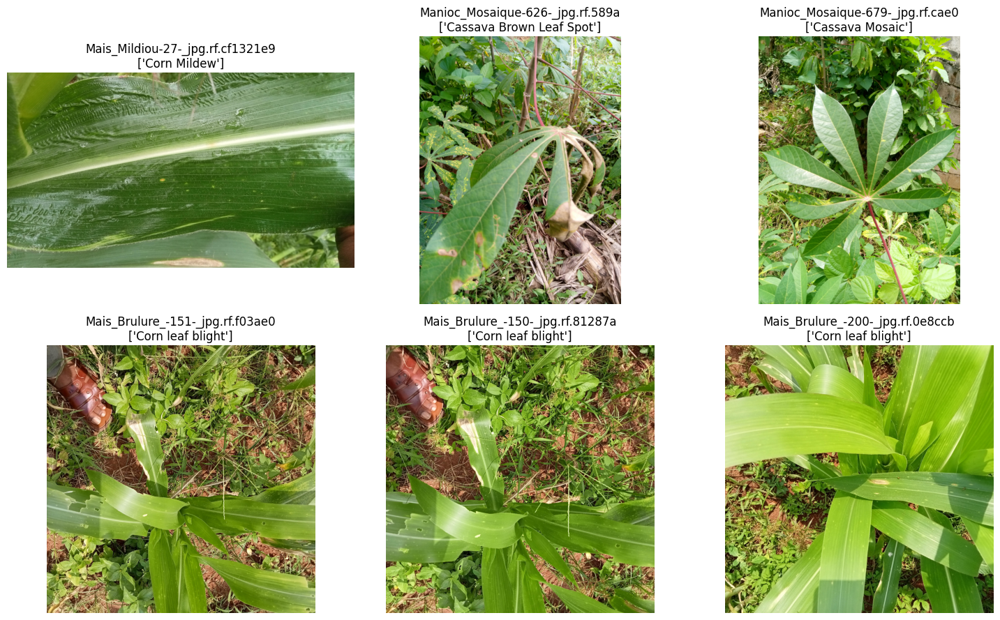


STEP 2 COMPLETED


In [2]:

# STEP 2: ANNOTATION AND LABEL ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

CSV_PATH = DATASET_PATH / "train" / "_annotations.csv"

df = pd.read_csv(CSV_PATH)

print("CSV SHAPE:", df.shape)
print("\nCOLUMNS:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nFIRST 10 RECORDS:")
display(df.head(10))

print("\nMISSING VALUES:")
display(df.isnull().sum())

# Identify annotation columns
class_col = next(
    (c for c in df.columns if c.lower() in
     ["class", "class_name", "label", "disease"]),
    None
)

filename_col = next(
    (c for c in df.columns if c.lower() in
     ["filename", "file_name", "image", "image_path"]),
    None
)

print("\nDETECTED CLASS COLUMN:", class_col)
print("DETECTED IMAGE COLUMN:", filename_col)

if class_col:
    print("\nANNOTATION CLASS DISTRIBUTION:")
    display(df[class_col].value_counts().to_frame("annotations"))

    print("NUMBER OF CLASSES:", df[class_col].nunique())

if filename_col:
    print("\nUNIQUE ANNOTATED IMAGES:", df[filename_col].nunique())
    print("TOTAL ANNOTATION ROWS:", len(df))

    print("\nANNOTATIONS PER IMAGE:")
    display(
        df.groupby(filename_col).size()
        .describe()
        .to_frame("annotations_per_image")
    )

# Verify image paths
if filename_col:
    image_lookup = {
        p.name: p for p in DATASET_PATH.rglob("*")
        if p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    }

    df["resolved_path"] = df[filename_col].map(
        lambda x: str(image_lookup[x])
        if x in image_lookup else None
    )

    print("\nMATCHED IMAGE ROWS:", df["resolved_path"].notna().sum())
    print("UNMATCHED IMAGE ROWS:", df["resolved_path"].isna().sum())

# Preview annotated images
if filename_col and class_col:
    sample_names = df[filename_col].drop_duplicates().sample(
        min(6, df[filename_col].nunique()),
        random_state=42
    )

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    axes = axes.flatten()

    for ax, name in zip(axes, sample_names):
        path = image_lookup.get(name)

        if path is not None:
            img = Image.open(path).convert("RGB")
            ax.imshow(img)
            labels = df.loc[
                df[filename_col] == name, class_col
            ].unique()
            ax.set_title(f"{name[:32]}\n{labels}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("\nSTEP 2 COMPLETED")


UNIQUE IMAGES: 5156
SINGLE-LABEL IMAGES: 4967
MULTI-LABEL IMAGES: 189

MULTI-LABEL EXAMPLES:


,filename,labels,num_boxes
332,IMG_20221118_080541_230_jpg.rf.bb3c818d13bfb12...,"[Tomato blight leaf, Tomato healthy]",2
334,IMG_20221118_080744_244_jpg.rf.fe42f45581f1b9d...,"[Tomato blight leaf, Tomato healthy]",2
337,IMG_20221118_080835_826_jpg.rf.72d4108d2e1ea67...,"[Tomato blight leaf, Tomato healthy]",4
338,IMG_20221118_080842_553_jpg.rf.36b09287d56f5b2...,"[Tomato blight leaf, Tomato healthy]",4
340,IMG_20221118_080929_762_jpg.rf.343cc6269533484...,"[Tomato blight leaf, Tomato healthy]",2
341,IMG_20221118_080945_246_jpg.rf.b055b612a7d1443...,"[Tomato blight leaf, Tomato healthy]",4
342,IMG_20221118_081009_764_jpg.rf.6f92f1858ff816a...,"[Tomato blight leaf, Tomato healthy]",2
343,IMG_20221118_081021_027_jpg.rf.894caed495eca5e...,"[Tomato blight leaf, Tomato healthy]",2
344,IMG_20221118_081044_718_jpg.rf.b68515db33ac4ea...,"[Tomato blight leaf, Tomato healthy]",2
351,IMG_20221118_081307_403_jpg.rf.d1daa7503ba787b...,"[Tomato blight leaf, Tomato healthy]",4



IMAGE-LEVEL CLASS DISTRIBUTION:


,class,image_count
3,Corn leaf blight,1111
24,Cassava Mosaic,1077
4,Tomato Brown Spots,952
6,Tomato blight leaf,359
8,Corn Yellowing,307
15,Cassava Healthy,264
23,Cassava Brown Leaf Spot,192
11,Corn Streak,182
18,Corn Brown Spots,172
7,Tomato healthy,141


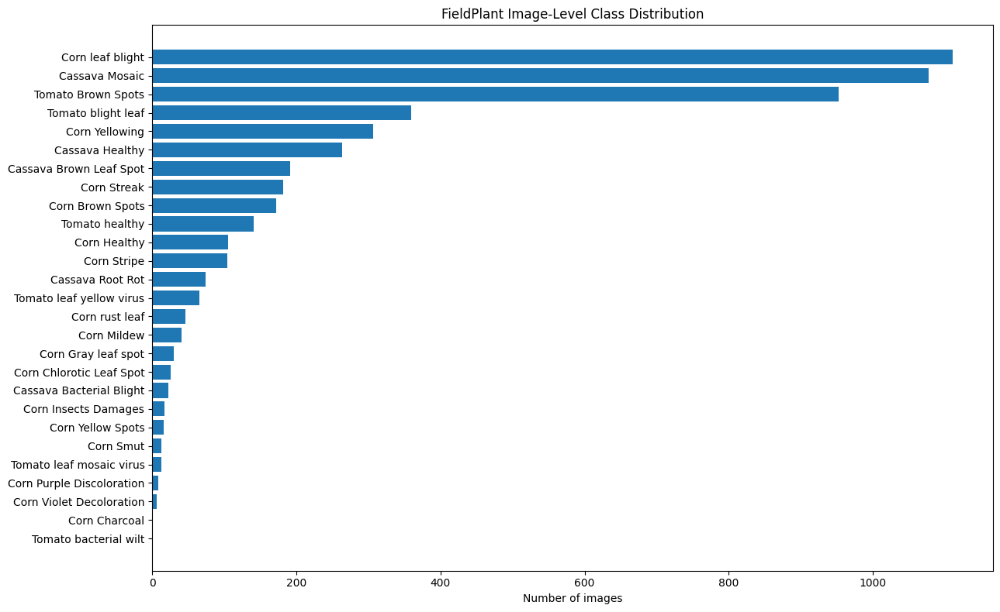


BOUNDING BOX AUDIT
Total boxes: 8580
Valid boxes: 8580
Invalid boxes: 0

DIMENSION MISMATCHES: 0

EXACT DUPLICATE AUDIT
Unique hashes: 4925
Duplicate groups: 231
Images involved in duplicate groups: 462

STEP 3 COMPLETED


In [3]:

# STEP 3: IMAGE-LEVEL LABEL AND DATA QUALITY AUDIT

import hashlib
from collections import Counter

df = pd.read_csv(CSV_PATH)

image_lookup = {
    p.name: p for p in DATASET_PATH.rglob("*")
    if p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
}

# Aggregate annotations by image
image_records = []

for filename, group in df.groupby("filename"):
    labels = sorted(group["class"].unique().tolist())
    first = group.iloc[0]

    image_records.append({
        "filename": filename,
        "path": str(image_lookup[filename]),
        "width": int(first["width"]),
        "height": int(first["height"]),
        "num_boxes": len(group),
        "num_classes": len(labels),
        "labels": labels,
        "label": labels[0] if len(labels) == 1 else "MULTI_LABEL"
    })

image_df = pd.DataFrame(image_records)

# Check images with multiple disease classes
print("UNIQUE IMAGES:", len(image_df))
print("SINGLE-LABEL IMAGES:",
      (image_df["num_classes"] == 1).sum())
print("MULTI-LABEL IMAGES:",
      (image_df["num_classes"] > 1).sum())

multi_df = image_df[image_df["num_classes"] > 1]

print("\nMULTI-LABEL EXAMPLES:")
display(multi_df[["filename", "labels", "num_boxes"]].head(20))

# Image-level class distribution
class_image_counts = Counter()

for labels in image_df["labels"]:
    class_image_counts.update(labels)

class_distribution = pd.DataFrame(
    class_image_counts.items(),
    columns=["class", "image_count"]
).sort_values("image_count", ascending=False)

print("\nIMAGE-LEVEL CLASS DISTRIBUTION:")
display(class_distribution)

plt.figure(figsize=(13, 8))
plt.barh(
    class_distribution["class"][::-1],
    class_distribution["image_count"][::-1]
)
plt.xlabel("Number of images")
plt.title("FieldPlant Image-Level Class Distribution")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "image_level_class_distribution.png",
    dpi=300
)
plt.show()

# Validate bounding boxes
bbox_valid = (
    (df["xmin"] >= 0) &
    (df["ymin"] >= 0) &
    (df["xmax"] <= df["width"]) &
    (df["ymax"] <= df["height"]) &
    (df["xmax"] > df["xmin"]) &
    (df["ymax"] > df["ymin"])
)

print("\nBOUNDING BOX AUDIT")
print("Total boxes:", len(df))
print("Valid boxes:", bbox_valid.sum())
print("Invalid boxes:", (~bbox_valid).sum())

# Check annotation dimensions against actual images
dimension_mismatches = []

for filename, group in df.groupby("filename"):
    path = image_lookup[filename]

    with Image.open(path) as img:
        actual_width, actual_height = img.size

    expected_width = int(group.iloc[0]["width"])
    expected_height = int(group.iloc[0]["height"])

    if (actual_width, actual_height) != (
        expected_width, expected_height
    ):
        dimension_mismatches.append({
            "filename": filename,
            "annotation_size": (
                expected_width, expected_height
            ),
            "actual_size": (actual_width, actual_height)
        })

print("\nDIMENSION MISMATCHES:",
      len(dimension_mismatches))

# Exact duplicate detection
hash_groups = {}

for filename, path in image_lookup.items():
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_groups.setdefault(digest, []).append(filename)

duplicate_groups = [
    names for names in hash_groups.values()
    if len(names) > 1
]

print("\nEXACT DUPLICATE AUDIT")
print("Unique hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Images involved in duplicate groups:",
      sum(len(x) for x in duplicate_groups))

# Save audit outputs
image_df.to_csv(
    TABLE_DIR / "image_level_metadata.csv",
    index=False
)

class_distribution.to_csv(
    TABLE_DIR / "image_level_class_distribution.csv",
    index=False
)

pd.DataFrame(dimension_mismatches).to_csv(
    TABLE_DIR / "dimension_mismatches.csv",
    index=False
)

with open(OUTPUT_DIR / "duplicate_groups.json", "w") as f:
    json.dump(duplicate_groups, f, indent=2)

print("\nSTEP 3 COMPLETED")


In [4]:

# STEP 4: DUPLICATE AND CLASS FEASIBILITY AUDIT

from collections import Counter
import hashlib

df = pd.read_csv(CSV_PATH)

# Rebuild image-level labels
image_labels = (
    df.groupby("filename")["class"]
    .apply(lambda x: sorted(set(x)))
    .to_dict()
)

image_lookup = {
    p.name: p for p in DATASET_PATH.rglob("*")
    if p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
}

# Recalculate duplicate groups
hash_groups = {}

for filename, path in image_lookup.items():
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_groups.setdefault(digest, []).append(filename)

duplicate_groups = [
    names for names in hash_groups.values()
    if len(names) > 1
]

# Check duplicate annotation consistency
duplicate_audit = []

for group_id, names in enumerate(duplicate_groups):
    label_sets = [set(image_labels[n]) for n in names]

    duplicate_audit.append({
        "group_id": group_id,
        "files": names,
        "labels": [sorted(x) for x in label_sets],
        "consistent": all(x == label_sets[0] for x in label_sets)
    })

duplicate_df = pd.DataFrame(duplicate_audit)

print("DUPLICATE GROUPS:", len(duplicate_df))
print("CONSISTENT GROUPS:",
      duplicate_df["consistent"].sum())
print("CONFLICTING GROUPS:",
      (~duplicate_df["consistent"]).sum())

print("\nCONFLICTING DUPLICATE EXAMPLES:")
display(
    duplicate_df[
        ~duplicate_df["consistent"]
    ].head(20)
)

# Count independent visual groups per class
class_group_counts = Counter()

for row in duplicate_audit:
    labels = set().union(
        *[set(x) for x in row["labels"]]
    )
    for label in labels:
        class_group_counts[label] += 1

duplicated_files = set(
    name for group in duplicate_groups for name in group
)

for filename in image_labels:
    if filename not in duplicated_files:
        for label in image_labels[filename]:
            class_group_counts[label] += 1

# Class feasibility
class_counts = Counter()

for labels in image_labels.values():
    class_counts.update(labels)

feasibility = pd.DataFrame([
    {
        "class": label,
        "image_count": class_counts[label],
        "independent_visual_groups": class_group_counts[label],
        "eligible_20": class_group_counts[label] >= 20,
        "eligible_10": class_group_counts[label] >= 10
    }
    for label in sorted(class_counts)
]).sort_values("image_count", ascending=False)

print("\nCLASS FEASIBILITY:")
display(feasibility)

print("\nCLASSES WITH AT LEAST 20 INDEPENDENT GROUPS:",
      (feasibility["independent_visual_groups"] >= 20).sum())

print("CLASSES WITH FEWER THAN 10 GROUPS:",
      (feasibility["independent_visual_groups"] < 10).sum())

# Multi-label co-occurrence
cooccurrence = Counter()

for labels in image_labels.values():
    if len(labels) > 1:
        for label in labels:
            cooccurrence[label] += 1

print("\nMULTI-LABEL CLASS OCCURRENCES:")
display(
    pd.DataFrame(
        cooccurrence.items(),
        columns=["class", "multi_label_images"]
    ).sort_values("multi_label_images", ascending=False)
)

duplicate_df.to_json(
    OUTPUT_DIR / "duplicate_audit.json",
    orient="records",
    indent=2
)

feasibility.to_csv(
    TABLE_DIR / "class_feasibility.csv",
    index=False
)

print("\nSTEP 4 COMPLETED")


DUPLICATE GROUPS: 231
CONSISTENT GROUPS: 194
CONFLICTING GROUPS: 37

CONFLICTING DUPLICATE EXAMPLES:


,group_id,files,labels,consistent
0,0,[Manioc_Mosaique-866-_jpg.rf.32b160f94b93e2c58...,"[[Cassava Mosaic], [Cassava Root Rot]]",False
2,2,[IMG20221216173649_jpg.rf.a44fc1895b67753ba699...,"[[Corn leaf blight], [Corn rust leaf]]",False
6,6,[Manioc_Mosaique-811-_jpg.rf.d612b88393ce00a57...,"[[Cassava Brown Leaf Spot], [Cassava Root Rot]]",False
9,9,[Manioc_Bacteriose-96-_jpg.rf.430820c838ac093e...,"[[Cassava Root Rot], [Cassava Mosaic]]",False
10,10,[Manioc_Mosaique-732-_jpg.rf.379f3ae7acfcacfe1...,"[[Cassava Mosaic], [Cassava Brown Leaf Spot]]",False
23,23,[IMG20221216173642_jpg.rf.61f3abf679e9690e521b...,"[[Corn leaf blight], [Corn rust leaf]]",False
40,40,[Manioc_Mosaique-723-_jpg.rf.32d25435838b6aaf5...,"[[Cassava Mosaic], [Cassava Brown Leaf Spot]]",False
46,46,[IMG_20221220_111408_jpg.rf.4994a3bebe3d4f0ff0...,"[[Tomato leaf yellow virus], [Tomato blight le...",False
68,68,[Manioc_Bacteriose-109-_jpg.rf.0bb6388dcc223e6...,"[[Cassava Root Rot], [Cassava Mosaic]]",False
80,80,[Mais_Striure-9-_jpg.rf.d8592fe8a69a6071ff8a71...,"[[Corn Streak], [Corn leaf blight]]",False



CLASS FEASIBILITY:


,class,image_count,independent_visual_groups,eligible_20,eligible_10
19,Corn leaf blight,1111,1111,True,True
3,Cassava Mosaic,1077,1077,True,True
21,Tomato Brown Spots,952,763,True,True
23,Tomato blight leaf,359,359,True,True
18,Corn Yellowing,307,307,True,True
2,Cassava Healthy,264,264,True,True
1,Cassava Brown Leaf Spot,192,186,True,True
14,Corn Streak,182,182,True,True
5,Corn Brown Spots,172,172,True,True
24,Tomato healthy,141,141,True,True



CLASSES WITH AT LEAST 20 INDEPENDENT GROUPS: 19
CLASSES WITH FEWER THAN 10 GROUPS: 4

MULTI-LABEL CLASS OCCURRENCES:


,class,multi_label_images
0,Tomato blight leaf,128
1,Tomato healthy,128
3,Corn Healthy,32
4,Corn leaf blight,32
8,Cassava Healthy,26
9,Cassava Mosaic,14
7,Cassava Brown Leaf Spot,13
6,Corn Brown Spots,2
5,Corn Stripe,2
2,Tomato leaf yellow virus,1



STEP 4 COMPLETED


Conflicting groups: 37
Affected files: 74


,group_id,filename,labels,box_count
0,0,Manioc_Mosaique-866-_jpg.rf.32b160f94b93e2c58f...,[Cassava Mosaic],1
1,0,Manioc_Bacteriose-95-_jpg.rf.871109a5d4b34a0b9...,[Cassava Root Rot],1
2,2,IMG20221216173649_jpg.rf.a44fc1895b67753ba699f...,[Corn leaf blight],1
3,2,Rouille_de_mais-22-_jpg.rf.86122fdcea9a33e3162...,[Corn rust leaf],1
4,6,Manioc_Mosaique-811-_jpg.rf.d612b88393ce00a579...,[Cassava Brown Leaf Spot],1
5,6,Manioc_Bacteriose-59-_jpg.rf.2565d15de6cb2f138...,[Cassava Root Rot],1
6,9,Manioc_Bacteriose-96-_jpg.rf.430820c838ac093e8...,[Cassava Root Rot],1
7,9,Manioc_Mosaique-867-_jpg.rf.7f290c656eaf7271d4...,[Cassava Mosaic],1
8,10,Manioc_Mosaique-732-_jpg.rf.379f3ae7acfcacfe1c...,[Cassava Mosaic],1
9,10,Manioc_Taches_Brunes-81-_jpg.rf.0d767c84e3d134...,[Cassava Brown Leaf Spot],1


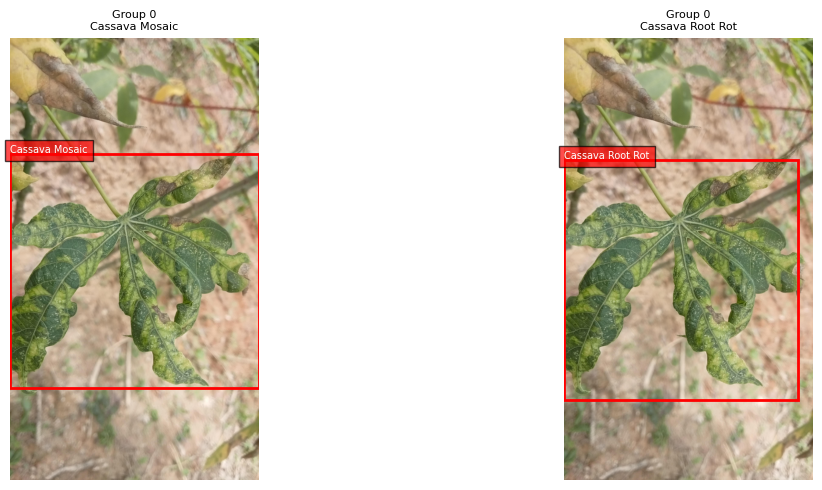

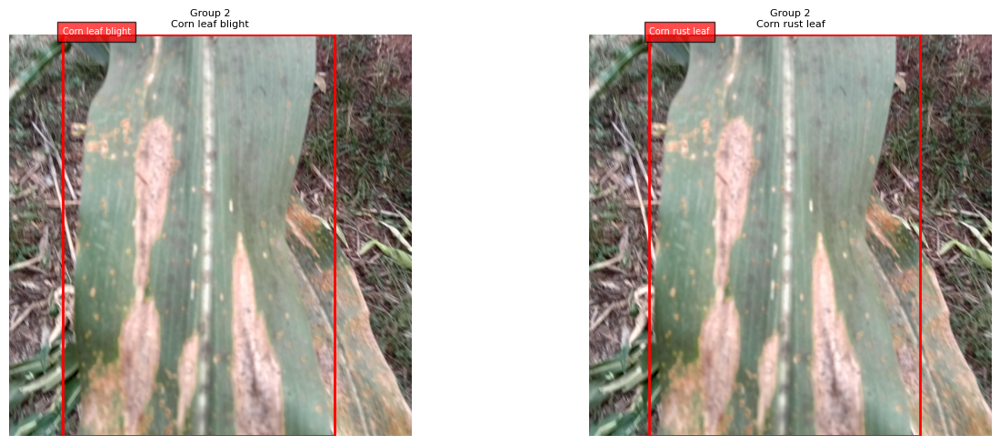

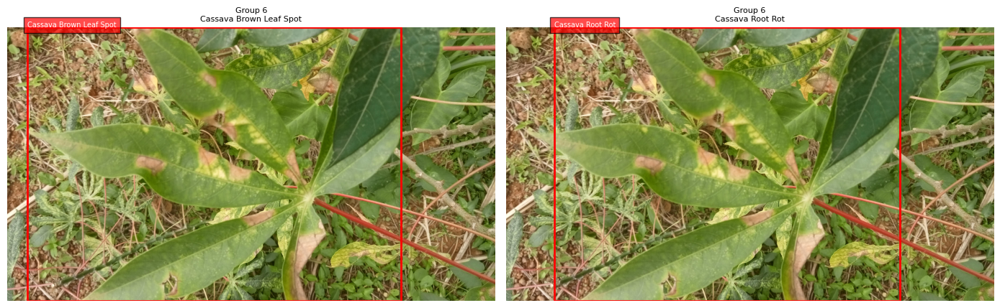

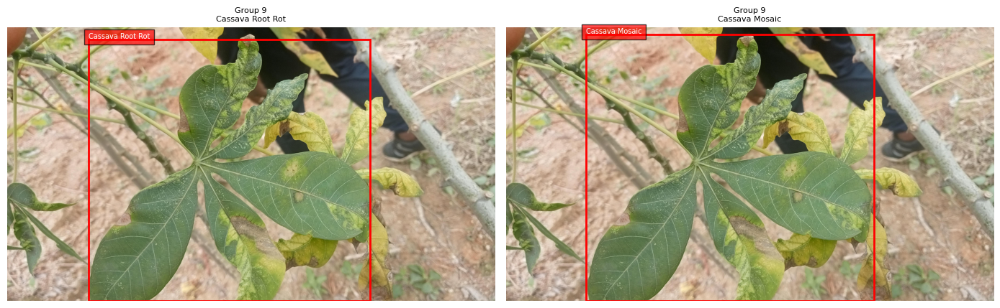

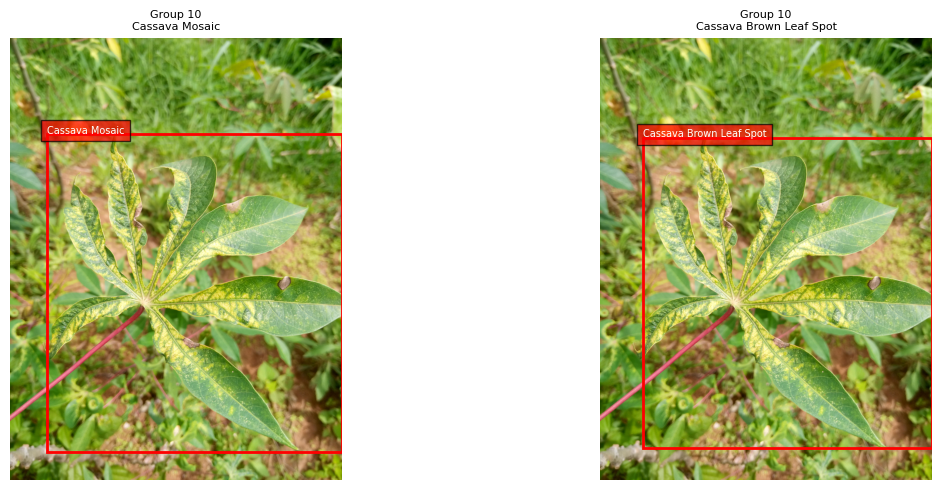

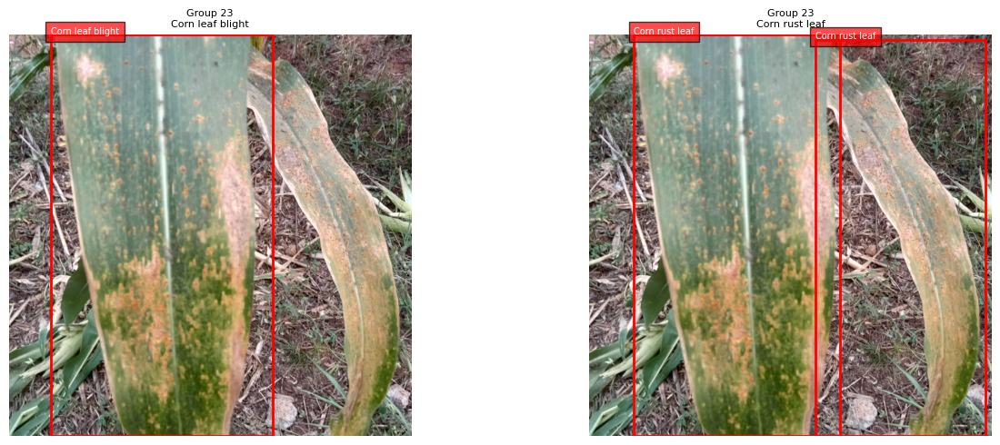

STEP 5 COMPLETED


In [5]:

# STEP 5: INSPECT CONFLICTING DUPLICATE ANNOTATIONS

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import pandas as pd

conflict_groups = [
    row for row in duplicate_audit
    if not row["consistent"]
]

conflict_details = []

for group in conflict_groups:
    for filename in group["files"]:
        rows = df[df["filename"] == filename]

        conflict_details.append({
            "group_id": group["group_id"],
            "filename": filename,
            "labels": sorted(rows["class"].unique().tolist()),
            "box_count": len(rows),
            "boxes": rows[
                ["class", "xmin", "ymin", "xmax", "ymax"]
            ].to_dict("records")
        })

conflict_details_df = pd.DataFrame(conflict_details)

print("Conflicting groups:", len(conflict_groups))
print("Affected files:", len(conflict_details_df))

display(
    conflict_details_df[
        ["group_id", "filename", "labels", "box_count"]
    ].head(30)
)

# Visual comparison of the first six groups
for group in conflict_groups[:6]:

    fig, axes = plt.subplots(1, len(group["files"]),
                             figsize=(14, 5))

    if len(group["files"]) == 1:
        axes = [axes]

    for ax, filename in zip(axes, group["files"]):

        image = Image.open(image_lookup[filename]).convert("RGB")
        ax.imshow(image)

        rows = df[df["filename"] == filename]

        for _, box in rows.iterrows():
            rect = patches.Rectangle(
                (box["xmin"], box["ymin"]),
                box["xmax"] - box["xmin"],
                box["ymax"] - box["ymin"],
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )
            ax.add_patch(rect)

            ax.text(
                box["xmin"],
                max(0, box["ymin"] - 5),
                str(box["class"]),
                color="white",
                fontsize=7,
                bbox=dict(facecolor="red", alpha=0.7)
            )

        ax.set_title(
            f"Group {group['group_id']}\n"
            f"{', '.join(sorted(rows['class'].unique()))}",
            fontsize=8
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("STEP 5 COMPLETED")


In [6]:

# STEP 6: BUILD CLEANED IMAGE-LEVEL DATASET

import pandas as pd
from collections import Counter
import json

clean_records = []
excluded_conflicts = []

for digest, filenames in hash_groups.items():

    label_sets = [
        set(image_labels[name])
        for name in filenames
    ]

    # Exclude conflicting duplicate groups
    if not all(labels == label_sets[0] for labels in label_sets):
        excluded_conflicts.append({
            "hash": digest,
            "files": filenames,
            "labels": [sorted(x) for x in label_sets]
        })
        continue

    # Select one representative image
    canonical = sorted(filenames)[0]

    clean_records.append({
        "filename": canonical,
        "path": str(image_lookup[canonical]),
        "sha256": digest,
        "labels_all": sorted(label_sets[0]),
        "num_labels": len(label_sets[0]),
        "duplicate_file_count": len(filenames)
    })

clean_df = pd.DataFrame(clean_records)

# Count independent visual groups per class
class_counts_clean = Counter()

for labels in clean_df["labels_all"]:
    class_counts_clean.update(labels)

class_table = pd.DataFrame([
    {
        "class": label,
        "independent_groups": count
    }
    for label, count in class_counts_clean.items()
]).sort_values("independent_groups", ascending=False)

# Define primary classes using the predeclared 20-group threshold
PRIMARY_CLASSES = sorted(
    class_table.loc[
        class_table["independent_groups"] >= 20,
        "class"
    ].tolist()
)

# Create primary benchmark labels
clean_df["labels_primary"] = clean_df["labels_all"].apply(
    lambda labels: [
        label for label in labels
        if label in PRIMARY_CLASSES
    ]
)

primary_df = clean_df[
    clean_df["labels_primary"].map(len) > 0
].copy().reset_index(drop=True)

# Save cleaned metadata
clean_df.to_csv(
    TABLE_DIR / "cleaned_all_class_metadata.csv",
    index=False
)

primary_df.to_csv(
    TABLE_DIR / "primary_19_class_metadata.csv",
    index=False
)

class_table.to_csv(
    TABLE_DIR / "final_class_counts.csv",
    index=False
)

with open(OUTPUT_DIR / "excluded_conflicting_groups.json", "w") as f:
    json.dump(excluded_conflicts, f, indent=2)

# Summary
print("CLEANED DATASET SUMMARY")
print("Original annotated images:", len(image_labels))
print("Unique visual groups:", len(hash_groups))
print("Excluded conflicting groups:", len(excluded_conflicts))
print("Cleaned independent images:", len(clean_df))
print("Primary benchmark classes:", len(PRIMARY_CLASSES))
print("Primary benchmark images:", len(primary_df))

print("\nPRIMARY CLASSES:")
print(PRIMARY_CLASSES)

print("\nFINAL CLASS COUNTS:")
display(class_table)

print("\nMULTI-LABEL IMAGES IN PRIMARY DATASET:",
      (primary_df["labels_primary"].map(len) > 1).sum())

print("\nSTEP 6 COMPLETED")


CLEANED DATASET SUMMARY
Original annotated images: 5156
Unique visual groups: 4925
Excluded conflicting groups: 37
Cleaned independent images: 4888
Primary benchmark classes: 19
Primary benchmark images: 4816

PRIMARY CLASSES:
['Cassava Bacterial Blight', 'Cassava Brown Leaf Spot', 'Cassava Healthy', 'Cassava Mosaic', 'Cassava Root Rot', 'Corn Brown Spots', 'Corn Chlorotic Leaf Spot', 'Corn Gray leaf spot', 'Corn Healthy', 'Corn Mildew', 'Corn Streak', 'Corn Stripe', 'Corn Yellowing', 'Corn leaf blight', 'Corn rust leaf', 'Tomato Brown Spots', 'Tomato blight leaf', 'Tomato healthy', 'Tomato leaf yellow virus']

FINAL CLASS COUNTS:


,class,independent_groups
5,Corn leaf blight,1098
0,Cassava Mosaic,1061
3,Tomato Brown Spots,761
6,Tomato blight leaf,357
1,Corn Yellowing,305
12,Cassava Healthy,262
2,Corn Streak,178
8,Cassava Brown Leaf Spot,173
4,Corn Brown Spots,172
16,Tomato healthy,141



MULTI-LABEL IMAGES IN PRIMARY DATASET: 187

STEP 6 COMPLETED


In [7]:

# STEP 7: MULTI-LABEL STRATIFIED DATA SPLIT

!pip -q install iterative-stratification

import numpy as np
import pandas as pd
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

SEED = 42

# Build multi-hot label matrix
class_to_idx = {
    label: idx
    for idx, label in enumerate(PRIMARY_CLASSES)
}

Y = np.zeros(
    (len(primary_df), len(PRIMARY_CLASSES)),
    dtype=np.int32
)

for i, labels in enumerate(primary_df["labels_primary"]):
    for label in labels:
        Y[i, class_to_idx[label]] = 1

X_indices = np.arange(len(primary_df))

# First split: 70% train, 30% temporary
split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(X_indices, Y)
)

# Second split: 15% validation, 15% test
Y_temp = Y[temp_idx]

split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_rel, test_rel = next(
    split2.split(temp_idx, Y_temp)
)

val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]

# Create partitions
train_df = primary_df.iloc[train_idx].copy().reset_index(drop=True)
val_df = primary_df.iloc[val_idx].copy().reset_index(drop=True)
test_df = primary_df.iloc[test_idx].copy().reset_index(drop=True)

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

# Save partitions
train_df.to_csv(TABLE_DIR / "train_metadata.csv", index=False)
val_df.to_csv(TABLE_DIR / "validation_metadata.csv", index=False)
test_df.to_csv(TABLE_DIR / "test_metadata.csv", index=False)

# Verify leakage
train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
test_hashes = set(test_df["sha256"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

# Verify class representation
def split_distribution(data, split_name):
    counts = Counter()

    for labels in data["labels_primary"]:
        counts.update(labels)

    return pd.DataFrame([
        {
            "class": label,
            split_name: counts[label]
        }
        for label in PRIMARY_CLASSES
    ])

distribution = split_distribution(train_df, "train")
distribution = distribution.merge(
    split_distribution(val_df, "validation"),
    on="class"
)
distribution = distribution.merge(
    split_distribution(test_df, "test"),
    on="class"
)

print("SPLIT SUMMARY")
print("Train:", len(train_df), f"({len(train_df)/len(primary_df):.2%})")
print("Validation:", len(val_df), f"({len(val_df)/len(primary_df):.2%})")
print("Test:", len(test_df), f"({len(test_df)/len(primary_df):.2%})")

print("\nHASH LEAKAGE CHECK")
print("Train-validation overlap:", len(train_hashes & val_hashes))
print("Train-test overlap:", len(train_hashes & test_hashes))
print("Validation-test overlap:", len(val_hashes & test_hashes))

print("\nCLASS DISTRIBUTION BY SPLIT")
display(distribution)

print("\nCLASSES ABSENT FROM ANY SPLIT")
for split_name in ["train", "validation", "test"]:
    missing = distribution.loc[
        distribution[split_name] == 0, "class"
    ].tolist()
    print(split_name, ":", missing)

print("\nMULTI-LABEL IMAGE COUNTS")
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    count = (data["labels_primary"].map(len) > 1).sum()
    print(name, count)

print("\nSTEP 7 COMPLETED")


SPLIT SUMMARY
Train: 3369 (69.95%)
Validation: 719 (14.93%)
Test: 728 (15.12%)

HASH LEAKAGE CHECK
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

CLASS DISTRIBUTION BY SPLIT


,class,train,validation,test
0,Cassava Bacterial Blight,15,3,3
1,Cassava Brown Leaf Spot,121,26,26
2,Cassava Healthy,183,39,40
3,Cassava Mosaic,743,159,159
4,Cassava Root Rot,45,10,10
5,Corn Brown Spots,120,26,26
6,Corn Chlorotic Leaf Spot,18,4,4
7,Corn Gray leaf spot,21,4,5
8,Corn Healthy,73,16,16
9,Corn Mildew,28,6,6



CLASSES ABSENT FROM ANY SPLIT
train : []
validation : []
test : []

MULTI-LABEL IMAGE COUNTS
Train 133
Validation 28
Test 26

STEP 7 COMPLETED


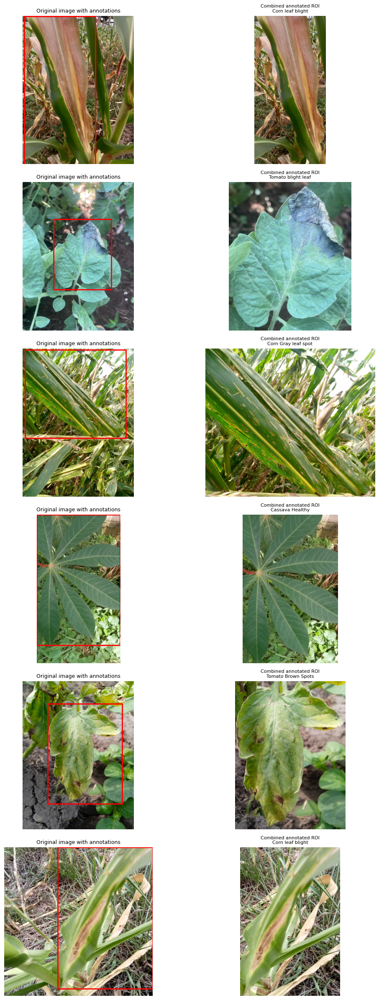

ROI ANNOTATION AUDIT
Valid ROI records: 4822
Invalid ROI records: 0

STEP 8 COMPLETED


In [8]:

# STEP 8: VISUAL INSPECTION OF TRAINING IMAGES AND ROIs

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

random.seed(42)

sample_rows = train_df.sample(
    n=min(6, len(train_df)),
    random_state=42
)

fig, axes = plt.subplots(6, 2, figsize=(12, 24))

roi_records = []
valid_roi_count = 0
invalid_roi_count = 0

for row_idx, (_, record) in enumerate(sample_rows.iterrows()):

    filename = record["filename"]
    image = Image.open(record["path"]).convert("RGB")

    annotations = df[df["filename"] == filename].copy()

    # Keep only primary-class annotations
    annotations = annotations[
        annotations["class"].isin(PRIMARY_CLASSES)
    ]

    width, height = image.size

    # Full image with bounding boxes
    axes[row_idx, 0].imshow(image)

    for _, box in annotations.iterrows():
        rect = patches.Rectangle(
            (box["xmin"], box["ymin"]),
            box["xmax"] - box["xmin"],
            box["ymax"] - box["ymin"],
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )
        axes[row_idx, 0].add_patch(rect)

    axes[row_idx, 0].set_title(
        "Original image with annotations",
        fontsize=9
    )
    axes[row_idx, 0].axis("off")

    # Combined ROI crop
    if len(annotations) > 0:

        x1 = max(0, int(annotations["xmin"].min()))
        y1 = max(0, int(annotations["ymin"].min()))
        x2 = min(width, int(annotations["xmax"].max()))
        y2 = min(height, int(annotations["ymax"].max()))

        if x2 > x1 and y2 > y1:
            roi = image.crop((x1, y1, x2, y2))
            axes[row_idx, 1].imshow(roi)
            valid_roi_count += 1
        else:
            axes[row_idx, 1].imshow(image)
            invalid_roi_count += 1

    else:
        axes[row_idx, 1].imshow(image)
        invalid_roi_count += 1

    axes[row_idx, 1].set_title(
        "Combined annotated ROI\n" +
        ", ".join(record["labels_primary"]),
        fontsize=8
    )
    axes[row_idx, 1].axis("off")

plt.tight_layout()
plt.show()

# Audit all primary images
for _, record in primary_df.iterrows():

    annotations = df[
        df["filename"] == record["filename"]
    ]

    annotations = annotations[
        annotations["class"].isin(PRIMARY_CLASSES)
    ]

    if len(annotations) == 0:
        invalid_roi_count += 1
        continue

    width = int(annotations.iloc[0]["width"])
    height = int(annotations.iloc[0]["height"])

    x1 = max(0, int(annotations["xmin"].min()))
    y1 = max(0, int(annotations["ymin"].min()))
    x2 = min(width, int(annotations["xmax"].max()))
    y2 = min(height, int(annotations["ymax"].max()))

    if x2 > x1 and y2 > y1:
        valid_roi_count += 1

print("ROI ANNOTATION AUDIT")
print("Valid ROI records:", valid_roi_count)
print("Invalid ROI records:", invalid_roi_count)

print("\nSTEP 8 COMPLETED")


In [9]:

# STEP 9: PYTORCH DATASET AND TRANSFORMS

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import pandas as pd

IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = len(PRIMARY_CLASSES)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.15
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FieldPlantDataset(Dataset):

    def __init__(self, metadata, annotation_df,
                 transform=None):

        self.data = metadata.reset_index(drop=True)
        self.annotations = annotation_df
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        record = self.data.iloc[index]
        filename = record["filename"]

        image = Image.open(record["path"]).convert("RGB")

        boxes = self.annotations[
            (self.annotations["filename"] == filename) &
            (self.annotations["class"].isin(PRIMARY_CLASSES))
        ]

        width, height = image.size

        x1 = int(boxes["xmin"].min())
        y1 = int(boxes["ymin"].min())
        x2 = int(boxes["xmax"].max())
        y2 = int(boxes["ymax"].max())

        x1 = max(0, min(x1, width - 1))
        y1 = max(0, min(y1, height - 1))
        x2 = max(x1 + 1, min(x2, width))
        y2 = max(y1 + 1, min(y2, height))

        roi = image.crop((x1, y1, x2, y2))

        # Apply identical transform parameters to both views
        if self.transform is not None:
            seed = torch.randint(0, 2**31, (1,)).item()

            torch.manual_seed(seed)
            global_tensor = self.transform(image)

            torch.manual_seed(seed)
            roi_tensor = self.transform(roi)

        else:
            global_tensor = eval_transform(image)
            roi_tensor = eval_transform(roi)

        target = torch.zeros(NUM_CLASSES, dtype=torch.float32)

        for label in record["labels_primary"]:
            target[class_to_idx[label]] = 1.0

        return {
            "global_image": global_tensor,
            "roi_image": roi_tensor,
            "target": target,
            "filename": filename
        }

train_dataset = FieldPlantDataset(
    train_df, df, train_transform
)

val_dataset = FieldPlantDataset(
    val_df, df, eval_transform
)

test_dataset = FieldPlantDataset(
    test_df, df, eval_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

# Verify one batch
batch = next(iter(train_loader))

print("Global image shape:", batch["global_image"].shape)
print("ROI image shape:", batch["roi_image"].shape)
print("Target shape:", batch["target"].shape)
print("Labels in first sample:",
      train_df.iloc[0]["labels_primary"])

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nSTEP 9 COMPLETED")


Global image shape: torch.Size([16, 3, 224, 224])
ROI image shape: torch.Size([16, 3, 224, 224])
Target shape: torch.Size([16, 19])
Labels in first sample: ['Cassava Mosaic']
Train batches: 211
Validation batches: 45
Test batches: 46

STEP 9 COMPLETED


In [11]:

# STEP 10A: DEFINE COMPUTE DEVICE

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


Selected device: cpu
Running on CPU


In [12]:
model = RCS_IRL(
    num_classes=NUM_CLASSES,
    pretrained=True
).to(device)

ImageNet pretrained ResNet-50 loaded.


In [13]:

# FAST CPU CONFIGURATION

import torch
import os

device = torch.device("cpu")

torch.set_num_threads(2)
torch.set_num_interop_threads(2)

BATCH_SIZE = 4
IMAGE_SIZE = 160

print("Device:", device)
print("CPU threads:", torch.get_num_threads())
print("Batch size:", BATCH_SIZE)
print("Image size:", IMAGE_SIZE)


Device: cpu
CPU threads: 2
Batch size: 4
Image size: 160


In [14]:

# FAST RCS-IRL MODEL - CPU VERSION

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

torch.set_num_threads(2)

IMAGE_SIZE = 160
BATCH_SIZE = 4

# Faster image transforms
train_transform_fast = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

eval_transform_fast = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

train_dataset_fast = FieldPlantDataset(
    train_df, df, train_transform_fast
)

val_dataset_fast = FieldPlantDataset(
    val_df, df, eval_transform_fast
)

test_dataset_fast = FieldPlantDataset(
    test_df, df, eval_transform_fast
)

train_loader = DataLoader(
    train_dataset_fast,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset_fast,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset_fast,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Fast ResNet-18 architecture
class RCS_IRL_Fast(nn.Module):

    def __init__(self, num_classes=19):
        super().__init__()

        backbone = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        backbone.fc = nn.Identity()
        self.backbone = backbone

        for p in self.backbone.parameters():
            p.requires_grad = False

        for p in self.backbone.layer4.parameters():
            p.requires_grad = True

        d = 512

        self.context_suppression = nn.Sequential(
            nn.Linear(d * 2, 128),
            nn.ReLU(),
            nn.Linear(128, d),
            nn.Sigmoid()
        )

        self.reliability_estimator = nn.Sequential(
            nn.Linear(d * 3, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        self.fusion = nn.Sequential(
            nn.Linear(d * 3, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Linear(256, num_classes)
        self.roi_classifier = nn.Linear(d, num_classes)
        self.global_classifier = nn.Linear(d, num_classes)

    def forward(self, global_image, roi_image):

        n = global_image.size(0)

        combined = torch.cat(
            [global_image, roi_image], dim=0
        )

        features = self.backbone(combined)

        global_features = features[:n]
        roi_features = features[n:]

        difference = torch.abs(
            roi_features - global_features
        )

        suppression = self.context_suppression(
            torch.cat(
                [roi_features, global_features], dim=1
            )
        )

        suppressed_context = (
            global_features * (1 - suppression)
        )

        reliability = self.reliability_estimator(
            torch.cat(
                [roi_features, global_features, difference],
                dim=1
            )
        )

        reliable_context = (
            suppressed_context * reliability
        )

        fused = self.fusion(
            torch.cat(
                [roi_features, reliable_context, difference],
                dim=1
            )
        )

        return {
            "logits": self.classifier(fused),
            "roi_logits": self.roi_classifier(roi_features),
            "global_logits": self.global_classifier(global_features),
            "reliability": reliability,
            "suppression_mask": suppression,
            "features": fused
        }


model = RCS_IRL_Fast(NUM_CLASSES).to(device)

# Forward-pass check
batch = next(iter(train_loader))

model.eval()

with torch.no_grad():
    output = model(
        batch["global_image"].to(device),
        batch["roi_image"].to(device)
    )

print("Device:", device)
print("Backbone: ResNet-18")
print("Input size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters()
          if p.requires_grad))

for name, value in output.items():
    print(name, tuple(value.shape))

print("FAST MODEL READY")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 44.6MB/s]


Device: cpu
Backbone: ResNet-18
Input size: 160
Batch size: 4
Trainable parameters: 9206202
logits (4, 19)
roi_logits (4, 19)
global_logits (4, 19)
reliability (4, 1)
suppression_mask (4, 512)
features (4, 256)
FAST MODEL READY


In [15]:

# STEP 11: RCS-IRL LOSS AND TRAINING SETUP

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Class imbalance weights from training data
train_targets = np.zeros(
    (len(train_df), NUM_CLASSES),
    dtype=np.float32
)

for i, labels in enumerate(train_df["labels_primary"]):
    for label in labels:
        train_targets[i, class_to_idx[label]] = 1

positive = train_targets.sum(axis=0)
negative = len(train_targets) - positive

pos_weights = negative / np.maximum(positive, 1)
pos_weights = np.clip(pos_weights, 1.0, 10.0)

pos_weights = torch.tensor(
    pos_weights, dtype=torch.float32
).to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weights
)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=1e-4,
    weight_decay=1e-4
)

def rcs_irl_loss(output, perturbed_output, targets):

    main_loss = criterion(
        output["logits"], targets
    )

    roi_loss = criterion(
        output["roi_logits"], targets
    )

    global_loss = criterion(
        output["global_logits"], targets
    )

    original_prob = torch.sigmoid(
        output["logits"]
    )

    perturbed_prob = torch.sigmoid(
        perturbed_output["logits"]
    )

    consistency_loss = F.mse_loss(
        original_prob, perturbed_prob
    )

    # Prediction agreement provides the reliability target
    stability_target = (
        1.0 - torch.abs(
            original_prob.detach() -
            perturbed_prob.detach()
        ).mean(dim=1, keepdim=True)
    ).clamp(0, 1)

    reliability_loss = F.mse_loss(
        output["reliability"],
        stability_target
    )

    total_loss = (
        main_loss
        + 0.25 * roi_loss
        + 0.15 * global_loss
        + 0.20 * consistency_loss
        + 0.10 * reliability_loss
    )

    return total_loss, {
        "main": main_loss,
        "roi": roi_loss,
        "global": global_loss,
        "consistency": consistency_loss,
        "reliability": reliability_loss
    }


# Two-batch smoke test
model.train()

for step, batch in enumerate(train_loader):

    if step >= 2:
        break

    global_image = batch["global_image"].to(device)
    roi_image = batch["roi_image"].to(device)
    targets = batch["target"].to(device)

    # Mild photometric perturbation
    perturbed_image = (
        global_image * 0.95
        + 0.02
        + torch.randn_like(global_image) * 0.02
    )

    optimizer.zero_grad(set_to_none=True)

    output = model(global_image, roi_image)

    perturbed_output = model(
        perturbed_image, roi_image
    )

    loss, loss_parts = rcs_irl_loss(
        output, perturbed_output, targets
    )

    loss.backward()
    optimizer.step()

    print(f"\nSmoke test batch {step + 1}")
    print("Total loss:", round(loss.item(), 5))

    for name, value in loss_parts.items():
        print(name, round(value.item(), 5))

print("\nSTEP 11 SMOKE TEST COMPLETED")



Smoke test batch 1
Total loss: 1.16116
main 0.81808
roi 0.7894
global 0.82933
consistency 0.00772
reliability 0.19786

Smoke test batch 2
Total loss: 1.22398
main 0.88207
roi 0.86075
global 0.73906
consistency 0.00637
reliability 0.14593

STEP 11 SMOKE TEST COMPLETED


In [16]:

# STEP 12: FAST TRAINING PILOT

import time
import copy
import numpy as np
import torch
from sklearn.metrics import f1_score, accuracy_score

EPOCHS = 2
MAX_TRAIN_BATCHES = 100
best_val_f1 = -1

history = []

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def evaluate_model(model, loader):

    model.eval()
    all_targets = []
    all_probs = []
    total_loss = 0

    with torch.no_grad():

        for batch in loader:

            global_image = batch["global_image"].to(device)
            roi_image = batch["roi_image"].to(device)
            targets = batch["target"].to(device)

            output = model(global_image, roi_image)

            loss = criterion(output["logits"], targets)
            total_loss += loss.item()

            all_targets.append(targets.cpu().numpy())
            all_probs.append(
                torch.sigmoid(output["logits"]).cpu().numpy()
            )

    y_true = np.concatenate(all_targets)
    y_prob = np.concatenate(all_probs)
    y_pred = (y_prob >= 0.5).astype(int)

    macro_f1 = f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )

    micro_f1 = f1_score(
        y_true, y_pred, average="micro", zero_division=0
    )

    return {
        "loss": total_loss / len(loader),
        "macro_f1": macro_f1,
        "micro_f1": micro_f1
    }


for epoch in range(EPOCHS):

    start_time = time.time()
    model.train()

    running_loss = 0
    steps = 0

    for batch_idx, batch in enumerate(train_loader):

        if batch_idx >= MAX_TRAIN_BATCHES:
            break

        global_image = batch["global_image"].to(device)
        roi_image = batch["roi_image"].to(device)
        targets = batch["target"].to(device)

        # Mild input perturbation
        perturbed_image = (
            global_image * 0.95
            + 0.02
            + torch.randn_like(global_image) * 0.02
        )

        optimizer.zero_grad(set_to_none=True)

        output = model(global_image, roi_image)

        perturbed_output = model(
            perturbed_image, roi_image
        )

        loss, loss_parts = rcs_irl_loss(
            output, perturbed_output, targets
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=2.0
        )

        optimizer.step()

        running_loss += loss.item()
        steps += 1

        if (batch_idx + 1) % 25 == 0:
            print(
                f"Epoch {epoch+1} | "
                f"Batch {batch_idx+1}/{MAX_TRAIN_BATCHES} | "
                f"Loss {loss.item():.4f}"
            )

    train_loss = running_loss / max(steps, 1)

    val_metrics = evaluate_model(model, val_loader)

    epoch_time = time.time() - start_time

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "val_macro_f1": val_metrics["macro_f1"],
        "val_micro_f1": val_metrics["micro_f1"],
        "seconds": epoch_time
    })

    print(f"\nEPOCH {epoch+1} RESULTS")
    print("Training loss:", round(train_loss, 4))
    print("Validation loss:", round(val_metrics["loss"], 4))
    print("Validation macro F1:", round(val_metrics["macro_f1"], 4))
    print("Validation micro F1:", round(val_metrics["micro_f1"], 4))
    print("Time:", round(epoch_time, 1), "seconds")

    if val_metrics["macro_f1"] > best_val_f1:

        best_val_f1 = val_metrics["macro_f1"]

        torch.save({
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "epoch": epoch + 1,
            "val_macro_f1": best_val_f1
        }, CHECKPOINT_DIR / "rcs_irl_pilot_best.pth")

        print("Best pilot checkpoint saved.")

    print("-" * 50)


history_df = pd.DataFrame(history)
display(history_df)

history_df.to_csv(
    TABLE_DIR / "pilot_training_history.csv",
    index=False
)

print("PILOT TRAINING COMPLETED")


Epoch 1 | Batch 25/100 | Loss 0.8695
Epoch 1 | Batch 50/100 | Loss 0.7407
Epoch 1 | Batch 75/100 | Loss 0.5538
Epoch 1 | Batch 100/100 | Loss 0.8996

EPOCH 1 RESULTS
Training loss: 0.9688
Validation loss: 0.5824
Validation macro F1: 0.1411
Validation micro F1: 0.5319
Time: 445.8 seconds
Best pilot checkpoint saved.
--------------------------------------------------
Epoch 2 | Batch 25/100 | Loss 0.8562
Epoch 2 | Batch 50/100 | Loss 0.5004
Epoch 2 | Batch 75/100 | Loss 0.5750
Epoch 2 | Batch 100/100 | Loss 0.5429

EPOCH 2 RESULTS
Training loss: 0.7472
Validation loss: 0.4784
Validation macro F1: 0.2546
Validation micro F1: 0.6142
Time: 421.1 seconds
Best pilot checkpoint saved.
--------------------------------------------------


,epoch,train_loss,val_loss,val_macro_f1,val_micro_f1,seconds
0,1,0.968825,0.582414,0.141139,0.531927,445.782006
1,2,0.747200,0.478377,0.254554,0.614182,421.089438


PILOT TRAINING COMPLETED


In [17]:

# STEP 13: PER-CLASS VALIDATION ANALYSIS

import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    precision_recall_fscore_support,
    precision_recall_curve,
    f1_score
)

# Load best pilot checkpoint
checkpoint = torch.load(
    CHECKPOINT_DIR / "rcs_irl_pilot_best.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_targets = []
all_probs = []

with torch.no_grad():

    for batch in val_loader:

        global_image = batch["global_image"].to(device)
        roi_image = batch["roi_image"].to(device)

        output = model(global_image, roi_image)

        all_targets.append(batch["target"].numpy())
        all_probs.append(
            torch.sigmoid(output["logits"]).cpu().numpy()
        )

y_true = np.concatenate(all_targets)
y_prob = np.concatenate(all_probs)

# Evaluate at the default threshold
y_pred_default = (y_prob >= 0.5).astype(int)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_true,
        y_pred_default,
        average=None,
        zero_division=0
    )
)

# Tune thresholds using validation predictions only
class_thresholds = []
tuned_f1 = []

for i in range(NUM_CLASSES):

    positives = int(y_true[:, i].sum())
    negatives = len(y_true) - positives

    if positives < 10 or negatives < 10:
        threshold = 0.5
        best_f1 = f1[i]
    else:
        p, r, thresholds = precision_recall_curve(
            y_true[:, i], y_prob[:, i]
        )

        scores = (
            2 * p[:-1] * r[:-1]
            / (p[:-1] + r[:-1] + 1e-8)
        )

        best_index = np.argmax(scores)
        threshold = float(thresholds[best_index])
        best_f1 = float(scores[best_index])

    class_thresholds.append(threshold)
    tuned_f1.append(best_f1)

# Create class-wise report
class_report = pd.DataFrame({
    "class": PRIMARY_CLASSES,
    "support": support,
    "precision_at_0.5": precision,
    "recall_at_0.5": recall,
    "f1_at_0.5": f1,
    "tuned_threshold": class_thresholds,
    "validation_f1_tuned": tuned_f1
})

class_report = class_report.sort_values(
    "f1_at_0.5"
).reset_index(drop=True)

display(class_report.round(4))

# Overall validation comparison
y_pred_tuned = (
    y_prob >= np.array(class_thresholds).reshape(1, -1)
).astype(int)

print("Default threshold macro-F1:",
      round(f1_score(
          y_true, y_pred_default,
          average="macro", zero_division=0
      ), 4))

print("Tuned validation macro-F1:",
      round(f1_score(
          y_true, y_pred_tuned,
          average="macro", zero_division=0
      ), 4))

# Save diagnostic outputs
class_report.to_csv(
    TABLE_DIR / "per_class_validation_report.csv",
    index=False
)

np.save(
    OUTPUT_DIR / "validation_class_thresholds.npy",
    np.array(class_thresholds)
)

print("STEP 13 COMPLETED")


,class,support,precision_at_0.5,recall_at_0.5,f1_at_0.5,tuned_threshold,validation_f1_tuned
0,Cassava Bacterial Blight,3,0.0000,0.0000,0.0000,0.5000,0.0000
1,Cassava Brown Leaf Spot,26,0.0000,0.0000,0.0000,0.3458,0.3284
2,Corn Chlorotic Leaf Spot,4,0.0000,0.0000,0.0000,0.5000,0.0000
3,Cassava Root Rot,10,0.0000,0.0000,0.0000,0.2666,0.1429
4,Corn Gray leaf spot,4,0.0000,0.0000,0.0000,0.5000,0.0000
5,Corn rust leaf,6,0.0000,0.0000,0.0000,0.5000,0.0000
6,Corn Stripe,15,0.0000,0.0000,0.0000,0.3620,0.4348
7,Corn Mildew,6,0.0000,0.0000,0.0000,0.5000,0.0000
8,Tomato leaf yellow virus,9,0.0000,0.0000,0.0000,0.5000,0.0000
9,Tomato healthy,21,0.0000,0.0000,0.0000,0.3721,0.3934


Default threshold macro-F1: 0.2546
Tuned validation macro-F1: 0.3698
STEP 13 COMPLETED


In [18]:

# STEP 14: CONSERVATIVE THRESHOLD CALIBRATION

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_recall_curve

safe_thresholds = []
calibration_status = []

for i in range(NUM_CLASSES):

    positives = int(y_true[:, i].sum())
    negatives = int(len(y_true) - positives)

    if positives >= 20 and negatives >= 20:

        p, r, thresholds = precision_recall_curve(
            y_true[:, i], y_prob[:, i]
        )

        scores = (
            2 * p[:-1] * r[:-1]
            / (p[:-1] + r[:-1] + 1e-8)
        )

        best_index = np.argmax(scores)
        threshold = float(thresholds[best_index])

        # Avoid extreme thresholds
        threshold = float(np.clip(threshold, 0.20, 0.80))

        status = "Tuned"

    else:
        threshold = 0.5
        status = "Default: insufficient validation support"

    safe_thresholds.append(threshold)
    calibration_status.append(status)

safe_thresholds = np.array(safe_thresholds)

safe_predictions = (
    y_prob >= safe_thresholds.reshape(1, -1)
).astype(int)

safe_macro_f1 = f1_score(
    y_true,
    safe_predictions,
    average="macro",
    zero_division=0
)

threshold_report = pd.DataFrame({
    "class": PRIMARY_CLASSES,
    "validation_support": y_true.sum(axis=0).astype(int),
    "threshold": safe_thresholds,
    "calibration": calibration_status
})

display(threshold_report)

print("Default macro-F1:", round(
    f1_score(y_true, y_pred_default, average="macro", zero_division=0), 4
))

print("Conservative calibrated macro-F1:", round(safe_macro_f1, 4))

np.save(
    OUTPUT_DIR / "conservative_validation_thresholds.npy",
    safe_thresholds
)

threshold_report.to_csv(
    TABLE_DIR / "conservative_threshold_report.csv",
    index=False
)

print("STEP 14 COMPLETED")


,class,validation_support,threshold,calibration
0,Cassava Bacterial Blight,3,0.500000,Default: insufficient validation support
1,Cassava Brown Leaf Spot,26,0.345752,Tuned
2,Cassava Healthy,39,0.490123,Tuned
3,Cassava Mosaic,159,0.701045,Tuned
4,Cassava Root Rot,10,0.500000,Default: insufficient validation support
5,Corn Brown Spots,26,0.475081,Tuned
6,Corn Chlorotic Leaf Spot,4,0.500000,Default: insufficient validation support
7,Corn Gray leaf spot,4,0.500000,Default: insufficient validation support
8,Corn Healthy,16,0.500000,Default: insufficient validation support
9,Corn Mildew,6,0.500000,Default: insufficient validation support


Default macro-F1: 0.2546
Conservative calibrated macro-F1: 0.3394
STEP 14 COMPLETED


In [19]:

# STEP 15: EXTRACT AND CACHE TRAINING FEATURES

from torch.utils.data import DataLoader, TensorDataset
import torch
import os
import time

# Use deterministic transforms for feature extraction
train_dataset_fast.transform = eval_transform_fast
val_dataset_fast.transform = eval_transform_fast

train_cache_loader = DataLoader(
    train_dataset_fast,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

val_cache_loader = DataLoader(
    val_dataset_fast,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

# Load best pilot model
checkpoint = torch.load(
    CHECKPOINT_DIR / "rcs_irl_pilot_best.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
model.backbone.eval()

def extract_feature_cache(loader, name):

    global_features_list = []
    roi_features_list = []
    targets_list = []

    start = time.time()

    with torch.no_grad():

        for batch_idx, batch in enumerate(loader):

            global_image = batch["global_image"].to(device)
            roi_image = batch["roi_image"].to(device)

            n = global_image.size(0)

            combined = torch.cat(
                [global_image, roi_image], dim=0
            )

            features = model.backbone(combined)

            global_features = features[:n]
            roi_features = features[n:]

            global_features_list.append(
                global_features.cpu()
            )

            roi_features_list.append(
                roi_features.cpu()
            )

            targets_list.append(
                batch["target"].cpu()
            )

            if (batch_idx + 1) % 100 == 0:
                print(
                    f"{name}: {batch_idx+1}/{len(loader)} batches"
                )

    result = {
        "global_features": torch.cat(global_features_list),
        "roi_features": torch.cat(roi_features_list),
        "targets": torch.cat(targets_list)
    }

    print(
        name,
        "samples:", len(result["targets"]),
        "feature shape:", result["global_features"].shape,
        "time:", round(time.time() - start, 1), "seconds"
    )

    return result


train_cache = extract_feature_cache(
    train_cache_loader, "Training"
)

val_cache = extract_feature_cache(
    val_cache_loader, "Validation"
)

torch.save(
    train_cache,
    OUTPUT_DIR / "train_feature_cache.pt"
)

torch.save(
    val_cache,
    OUTPUT_DIR / "validation_feature_cache.pt"
)

print("TRAIN AND VALIDATION FEATURE CACHES SAVED")


Training: 100/422 batches
Training: 200/422 batches
Training: 300/422 batches
Training: 400/422 batches
Training samples: 3369 feature shape: torch.Size([3369, 512]) time: 976.9 seconds
Validation samples: 719 feature shape: torch.Size([719, 512]) time: 187.0 seconds
TRAIN AND VALIDATION FEATURE CACHES SAVED


In [20]:

# STEP 16: FEATURE-LEVEL RCS-IRL MODEL

import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import time

class RCS_IRL_FeatureModel(nn.Module):

    def __init__(self, num_classes=19, feature_dim=512):

        super().__init__()

        self.context_suppression = nn.Sequential(
            nn.Linear(feature_dim * 2, 128),
            nn.ReLU(),
            nn.Linear(128, feature_dim),
            nn.Sigmoid()
        )

        self.reliability_estimator = nn.Sequential(
            nn.Linear(feature_dim * 3, 128),
            nn.ReLU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        self.fusion = nn.Sequential(
            nn.Linear(feature_dim * 3, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Linear(256, num_classes)
        self.roi_classifier = nn.Linear(feature_dim, num_classes)
        self.global_classifier = nn.Linear(feature_dim, num_classes)

    def forward(self, global_features, roi_features):

        difference = torch.abs(
            roi_features - global_features
        )

        suppression = self.context_suppression(
            torch.cat(
                [roi_features, global_features], dim=1
            )
        )

        suppressed_context = (
            global_features * (1 - suppression)
        )

        reliability = self.reliability_estimator(
            torch.cat(
                [roi_features, global_features, difference],
                dim=1
            )
        )

        reliable_context = suppressed_context * reliability

        fused = self.fusion(
            torch.cat(
                [roi_features, reliable_context, difference],
                dim=1
            )
        )

        return {
            "logits": self.classifier(fused),
            "roi_logits": self.roi_classifier(roi_features),
            "global_logits": self.global_classifier(global_features),
            "reliability": reliability,
            "suppression_mask": suppression,
            "features": fused
        }


feature_model = RCS_IRL_FeatureModel(
    num_classes=NUM_CLASSES
).to(device)

print("Feature-level RCS-IRL model created")
print("Trainable parameters:",
      sum(p.numel() for p in feature_model.parameters()
          if p.requires_grad))

# Load cached features
train_cache = torch.load(
    OUTPUT_DIR / "train_feature_cache.pt",
    map_location="cpu",
    weights_only=False
)

val_cache = torch.load(
    OUTPUT_DIR / "validation_feature_cache.pt",
    map_location="cpu",
    weights_only=False
)

train_feature_dataset = torch.utils.data.TensorDataset(
    train_cache["global_features"],
    train_cache["roi_features"],
    train_cache["targets"]
)

val_feature_dataset = torch.utils.data.TensorDataset(
    val_cache["global_features"],
    val_cache["roi_features"],
    val_cache["targets"]
)

train_feature_loader = torch.utils.data.DataLoader(
    train_feature_dataset,
    batch_size=64,
    shuffle=True
)

val_feature_loader = torch.utils.data.DataLoader(
    val_feature_dataset,
    batch_size=128,
    shuffle=False
)

print("Training feature batches:", len(train_feature_loader))
print("Validation feature batches:", len(val_feature_loader))
print("STEP 16 COMPLETED")


Feature-level RCS-IRL model created
Trainable parameters: 812474
Training feature batches: 53
Validation feature batches: 6
STEP 16 COMPLETED


In [21]:

# STEP 17: FEATURE-LEVEL TRAINING

import copy
import time
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score

# Class weights from training data
feature_pos = train_cache["targets"].sum(dim=0)
feature_neg = len(train_cache["targets"]) - feature_pos

feature_weights = (
    feature_neg / feature_pos.clamp(min=1)
).clamp(1, 10).to(device)

feature_criterion = nn.BCEWithLogitsLoss(
    pos_weight=feature_weights
)

feature_optimizer = torch.optim.AdamW(
    feature_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

def feature_loss_fn(output, perturbed_output, targets):

    main_loss = feature_criterion(
        output["logits"], targets
    )

    roi_loss = feature_criterion(
        output["roi_logits"], targets
    )

    global_loss = feature_criterion(
        output["global_logits"], targets
    )

    original_prob = torch.sigmoid(output["logits"])
    perturbed_prob = torch.sigmoid(
        perturbed_output["logits"]
    )

    consistency_loss = F.mse_loss(
        original_prob, perturbed_prob
    )

    stability_target = (
        1 - torch.abs(
            original_prob.detach()
            - perturbed_prob.detach()
        ).mean(dim=1, keepdim=True)
    ).clamp(0, 1)

    reliability_loss = F.mse_loss(
        output["reliability"],
        stability_target
    )

    total = (
        main_loss
        + 0.25 * roi_loss
        + 0.15 * global_loss
        + 0.20 * consistency_loss
        + 0.10 * reliability_loss
    )

    return total


def evaluate_feature_model():

    feature_model.eval()
    targets_all = []
    probabilities_all = []
    losses = []

    with torch.no_grad():

        for global_f, roi_f, targets in val_feature_loader:

            global_f = global_f.to(device)
            roi_f = roi_f.to(device)
            targets = targets.to(device)

            output = feature_model(global_f, roi_f)

            losses.append(
                feature_criterion(
                    output["logits"], targets
                ).item()
            )

            targets_all.append(targets.cpu().numpy())
            probabilities_all.append(
                torch.sigmoid(output["logits"]).cpu().numpy()
            )

    y = np.concatenate(targets_all)
    probabilities = np.concatenate(probabilities_all)
    predictions = (probabilities >= 0.5).astype(int)

    macro = f1_score(
        y, predictions, average="macro", zero_division=0
    )

    micro = f1_score(
        y, predictions, average="micro", zero_division=0
    )

    return np.mean(losses), macro, micro


EPOCHS = 30
PATIENCE = 6
best_score = -1
wait = 0
feature_history = []

for epoch in range(EPOCHS):

    start = time.time()
    feature_model.train()
    running_loss = 0

    for global_f, roi_f, targets in train_feature_loader:

        global_f = global_f.to(device)
        roi_f = roi_f.to(device)
        targets = targets.to(device)

        # Perturb global features for consistency training
        perturbed_global = (
            global_f
            + 0.03 * torch.randn_like(global_f)
        )

        feature_optimizer.zero_grad(set_to_none=True)

        output = feature_model(global_f, roi_f)

        perturbed_output = feature_model(
            perturbed_global, roi_f
        )

        loss = feature_loss_fn(
            output, perturbed_output, targets
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            feature_model.parameters(), 2.0
        )

        feature_optimizer.step()
        running_loss += loss.item()

    val_loss, val_macro, val_micro = evaluate_feature_model()

    epoch_loss = running_loss / len(train_feature_loader)
    elapsed = time.time() - start

    feature_history.append({
        "epoch": epoch + 1,
        "train_loss": epoch_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_macro,
        "val_micro_f1": val_micro,
        "seconds": elapsed
    })

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train loss {epoch_loss:.4f} | "
        f"Val loss {val_loss:.4f} | "
        f"Macro-F1 {val_macro:.4f} | "
        f"Micro-F1 {val_micro:.4f} | "
        f"{elapsed:.1f}s"
    )

    if val_macro > best_score:

        best_score = val_macro
        wait = 0

        torch.save(
            feature_model.state_dict(),
            CHECKPOINT_DIR / "rcs_irl_feature_best.pth"
        )

        print("Best feature model saved.")

    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping triggered.")
        break


feature_history_df = pd.DataFrame(feature_history)

display(feature_history_df)

feature_history_df.to_csv(
    TABLE_DIR / "feature_training_history.csv",
    index=False
)

print("Best validation macro-F1:", round(best_score, 4))
print("STEP 17 COMPLETED")


Epoch 01 | Train loss 0.5971 | Val loss 0.3056 | Macro-F1 0.3365 | Micro-F1 0.6018 | 2.5s
Best feature model saved.
Epoch 02 | Train loss 0.3733 | Val loss 0.2410 | Macro-F1 0.4297 | Micro-F1 0.6443 | 1.4s
Best feature model saved.
Epoch 03 | Train loss 0.2949 | Val loss 0.2143 | Macro-F1 0.4899 | Micro-F1 0.6970 | 1.4s
Best feature model saved.
Epoch 04 | Train loss 0.2445 | Val loss 0.2102 | Macro-F1 0.5101 | Micro-F1 0.7328 | 1.4s
Best feature model saved.
Epoch 05 | Train loss 0.2092 | Val loss 0.1966 | Macro-F1 0.5749 | Micro-F1 0.7317 | 4.0s
Best feature model saved.
Epoch 06 | Train loss 0.1803 | Val loss 0.2101 | Macro-F1 0.5546 | Micro-F1 0.7618 | 1.4s
Epoch 07 | Train loss 0.1540 | Val loss 0.2043 | Macro-F1 0.5643 | Micro-F1 0.7629 | 1.4s
Epoch 08 | Train loss 0.1352 | Val loss 0.2198 | Macro-F1 0.5488 | Micro-F1 0.7660 | 1.4s
Epoch 09 | Train loss 0.1219 | Val loss 0.2504 | Macro-F1 0.5669 | Micro-F1 0.7741 | 1.4s
Epoch 10 | Train loss 0.1100 | Val loss 0.2395 | Macro-F1 0.

,epoch,train_loss,val_loss,val_macro_f1,val_micro_f1,seconds
0,1,0.597056,0.305621,0.336536,0.601835,2.465911
1,2,0.373289,0.241014,0.429722,0.644308,1.428970
2,3,0.294882,0.214332,0.489880,0.696954,1.418723
3,4,0.244501,0.210234,0.510084,0.732816,1.393597
4,5,0.209245,0.196613,0.574876,0.731654,3.972995
5,6,0.180348,0.210128,0.554568,0.761849,1.382632
6,7,0.154007,0.204322,0.564277,0.762911,1.430952
7,8,0.135205,0.219834,0.548817,0.766008,1.389510
8,9,0.121923,0.250428,0.566897,0.774074,1.390638
9,10,0.110005,0.239511,0.564610,0.784887,1.411793


Best validation macro-F1: 0.5749
STEP 17 COMPLETED


In [22]:

# STEP 18: BEST MODEL VALIDATION EVALUATION

import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    precision_recall_curve,
    precision_recall_fscore_support
)

# Load best feature-level checkpoint
feature_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "rcs_irl_feature_best.pth",
        map_location=device,
        weights_only=True
    )
)

feature_model.eval()

targets_all = []
probs_all = []

with torch.no_grad():

    for global_f, roi_f, targets in val_feature_loader:

        global_f = global_f.to(device)
        roi_f = roi_f.to(device)

        output = feature_model(global_f, roi_f)

        targets_all.append(targets.numpy())

        probs_all.append(
            torch.sigmoid(output["logits"]).cpu().numpy()
        )

y_val = np.concatenate(targets_all)
p_val = np.concatenate(probs_all)

# Default threshold evaluation
pred_default = (p_val >= 0.5).astype(int)

default_macro = f1_score(
    y_val, pred_default,
    average="macro", zero_division=0
)

default_micro = f1_score(
    y_val, pred_default,
    average="micro", zero_division=0
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_val,
        pred_default,
        average=None,
        zero_division=0
    )
)

# Conservative class-wise calibration
feature_thresholds = []
calibrated_f1 = []

for i in range(NUM_CLASSES):

    positives = int(y_val[:, i].sum())
    negatives = len(y_val) - positives

    if positives >= 20 and negatives >= 20:

        pr, rc, thresholds = precision_recall_curve(
            y_val[:, i], p_val[:, i]
        )

        scores = (
            2 * pr[:-1] * rc[:-1]
            / (pr[:-1] + rc[:-1] + 1e-8)
        )

        best_index = np.argmax(scores)

        threshold = float(
            np.clip(thresholds[best_index], 0.20, 0.80)
        )

        best_f1 = float(scores[best_index])

    else:
        threshold = 0.5
        best_f1 = float(f1[i])

    feature_thresholds.append(threshold)
    calibrated_f1.append(best_f1)

feature_thresholds = np.array(feature_thresholds)

pred_calibrated = (
    p_val >= feature_thresholds.reshape(1, -1)
).astype(int)

calibrated_macro = f1_score(
    y_val,
    pred_calibrated,
    average="macro",
    zero_division=0
)

# Per-class report
report = pd.DataFrame({
    "class": PRIMARY_CLASSES,
    "support": support,
    "precision": precision,
    "recall": recall,
    "f1_default": f1,
    "threshold": feature_thresholds,
    "calibrated_f1": calibrated_f1
})

display(report.round(4))

print("Default macro-F1:", round(default_macro, 4))
print("Default micro-F1:", round(default_micro, 4))
print("Calibrated macro-F1:", round(calibrated_macro, 4))

report.to_csv(
    TABLE_DIR / "feature_model_validation_report.csv",
    index=False
)

np.save(
    OUTPUT_DIR / "feature_model_thresholds.npy",
    feature_thresholds
)

print("STEP 18 COMPLETED")


,class,support,precision,recall,f1_default,threshold,calibrated_f1
0,Cassava Bacterial Blight,3,0.4000,0.6667,0.5000,0.5000,0.5000
1,Cassava Brown Leaf Spot,26,0.2039,0.8077,0.3256,0.8000,0.6047
2,Cassava Healthy,39,0.5072,0.8974,0.6481,0.7520,0.7250
3,Cassava Mosaic,159,0.8563,0.9371,0.8949,0.5896,0.9046
4,Cassava Root Rot,10,0.5000,0.8000,0.6154,0.5000,0.6154
5,Corn Brown Spots,26,0.9412,0.6154,0.7442,0.4534,0.8085
6,Corn Chlorotic Leaf Spot,4,0.1053,0.5000,0.1739,0.5000,0.1739
7,Corn Gray leaf spot,4,0.0000,0.0000,0.0000,0.5000,0.0000
8,Corn Healthy,16,0.3261,0.9375,0.4839,0.5000,0.4839
9,Corn Mildew,6,0.1111,0.1667,0.1333,0.5000,0.1333


Default macro-F1: 0.5749
Default micro-F1: 0.7317
Calibrated macro-F1: 0.6066
STEP 18 COMPLETED


In [23]:

# STEP 19: FEATURE-SPACE ROBUSTNESS EVALUATION

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

feature_model.eval()

noise_levels = [0.00, 0.01, 0.03, 0.05, 0.10, 0.15]

robustness_results = []

# Use validation data only
with torch.no_grad():

    for noise_level in noise_levels:

        targets_all = []
        predictions_all = []

        for global_f, roi_f, targets in val_feature_loader:

            global_f = global_f.to(device)
            roi_f = roi_f.to(device)

            # Apply controlled perturbation to global features
            perturbed_global = (
                global_f
                + noise_level * torch.randn_like(global_f)
            )

            output = feature_model(
                perturbed_global, roi_f
            )

            probabilities = torch.sigmoid(
                output["logits"]
            )

            predictions = (
                probabilities >= 0.5
            ).int()

            targets_all.append(targets.numpy())
            predictions_all.append(
                predictions.cpu().numpy()
            )

        y_true_robust = np.concatenate(targets_all)
        y_pred_robust = np.concatenate(predictions_all)

        macro = f1_score(
            y_true_robust,
            y_pred_robust,
            average="macro",
            zero_division=0
        )

        micro = f1_score(
            y_true_robust,
            y_pred_robust,
            average="micro",
            zero_division=0
        )

        robustness_results.append({
            "noise_level": noise_level,
            "macro_f1": macro,
            "micro_f1": micro
        })

        print(
            f"Noise {noise_level:.2f} | "
            f"Macro-F1 {macro:.4f} | "
            f"Micro-F1 {micro:.4f}"
        )

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)

robustness_df.to_csv(
    TABLE_DIR / "feature_robustness_results.csv",
    index=False
)

print("STEP 19 COMPLETED")


Noise 0.00 | Macro-F1 0.5749 | Micro-F1 0.7317
Noise 0.01 | Macro-F1 0.5763 | Micro-F1 0.7323
Noise 0.03 | Macro-F1 0.5763 | Micro-F1 0.7321
Noise 0.05 | Macro-F1 0.5761 | Micro-F1 0.7319
Noise 0.10 | Macro-F1 0.5741 | Micro-F1 0.7313
Noise 0.15 | Macro-F1 0.5839 | Micro-F1 0.7357


,noise_level,macro_f1,micro_f1
0,0.00,0.574876,0.731654
1,0.01,0.576349,0.732348
2,0.03,0.576297,0.732055
3,0.05,0.576092,0.731947
4,0.10,0.574104,0.731253
5,0.15,0.583908,0.735683


STEP 19 COMPLETED


In [24]:

# STEP 20: FEATURE DISTRIBUTION AND NOISE AUDIT

import torch
import pandas as pd

global_features = val_cache["global_features"].float()
roi_features = val_cache["roi_features"].float()

def feature_statistics(features, name):

    values = features.flatten()

    return {
        "feature_type": name,
        "mean": values.mean().item(),
        "std": values.std().item(),
        "min": values.min().item(),
        "max": values.max().item(),
        "mean_absolute": values.abs().mean().item(),
        "rms": torch.sqrt(torch.mean(values ** 2)).item()
    }

stats = pd.DataFrame([
    feature_statistics(global_features, "Global"),
    feature_statistics(roi_features, "ROI")
])

display(stats.round(5))

print("Global feature shape:", global_features.shape)
print("ROI feature shape:", roi_features.shape)

print("\nRelative noise strengths:")

feature_std = global_features.std().item()

for level in [0.01, 0.03, 0.05, 0.10, 0.15]:
    print(
        f"Noise {level:.2f} = "
        f"{level / (feature_std + 1e-8) * 100:.2f}% "
        "of global feature standard deviation"
    )

stats.to_csv(
    TABLE_DIR / "feature_distribution_audit.csv",
    index=False
)

print("STEP 20 COMPLETED")


,feature_type,mean,std,min,max,mean_absolute,rms
0,Global,1.00699,1.10619,0.0,15.04085,1.00699,1.49589
1,ROI,1.06288,1.21481,0.0,17.49408,1.06288,1.61415


Global feature shape: torch.Size([719, 512])
ROI feature shape: torch.Size([719, 512])

Relative noise strengths:
Noise 0.01 = 0.90% of global feature standard deviation
Noise 0.03 = 2.71% of global feature standard deviation
Noise 0.05 = 4.52% of global feature standard deviation
Noise 0.10 = 9.04% of global feature standard deviation
Noise 0.15 = 13.56% of global feature standard deviation
STEP 20 COMPLETED


In [25]:

# STEP 21: REPEATED-SEED ROBUSTNESS EXPERIMENT

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Restore the best validation checkpoint
feature_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "rcs_irl_feature_best.pth",
        map_location=device,
        weights_only=True
    )
)

feature_model.eval()

noise_fractions = [0.00, 0.10, 0.20, 0.30, 0.50, 0.75]
seeds = [11, 22, 33, 44, 55]

global_std = train_cache["global_features"].std().item()
roi_std = train_cache["roi_features"].std().item()

corruption_modes = ["global", "roi", "both"]

results = []

for mode in corruption_modes:

    for fraction in noise_fractions:

        for seed in seeds:

            torch.manual_seed(seed)

            all_targets = []
            all_predictions = []

            with torch.no_grad():

                for global_f, roi_f, targets in val_feature_loader:

                    global_f = global_f.to(device)
                    roi_f = roi_f.to(device)

                    if mode in ["global", "both"]:
                        global_f = (
                            global_f
                            + fraction * global_std
                            * torch.randn_like(global_f)
                        )

                    if mode in ["roi", "both"]:
                        roi_f = (
                            roi_f
                            + fraction * roi_std
                            * torch.randn_like(roi_f)
                        )

                    output = feature_model(global_f, roi_f)

                    predictions = (
                        torch.sigmoid(output["logits"]) >= 0.5
                    ).int()

                    all_targets.append(targets.numpy())
                    all_predictions.append(
                        predictions.cpu().numpy()
                    )

            y_true_robust = np.concatenate(all_targets)
            y_pred_robust = np.concatenate(all_predictions)

            macro = f1_score(
                y_true_robust,
                y_pred_robust,
                average="macro",
                zero_division=0
            )

            micro = f1_score(
                y_true_robust,
                y_pred_robust,
                average="micro",
                zero_division=0
            )

            results.append({
                "mode": mode,
                "noise_fraction": fraction,
                "seed": seed,
                "macro_f1": macro,
                "micro_f1": micro
            })

        print(
            f"Completed {mode} | "
            f"Noise fraction {fraction:.2f}"
        )

robustness_repeated_df = pd.DataFrame(results)

summary = (
    robustness_repeated_df
    .groupby(["mode", "noise_fraction"])
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        micro_f1_mean=("micro_f1", "mean"),
        micro_f1_std=("micro_f1", "std")
    )
    .reset_index()
)

display(summary.round(4))

robustness_repeated_df.to_csv(
    TABLE_DIR / "repeated_seed_robustness_raw.csv",
    index=False
)

summary.to_csv(
    TABLE_DIR / "repeated_seed_robustness_summary.csv",
    index=False
)

print("Global feature standard deviation:", round(global_std, 4))
print("ROI feature standard deviation:", round(roi_std, 4))
print("Total evaluation runs:", len(results))
print("STEP 21 COMPLETED")


Completed global | Noise fraction 0.00
Completed global | Noise fraction 0.10
Completed global | Noise fraction 0.20
Completed global | Noise fraction 0.30
Completed global | Noise fraction 0.50
Completed global | Noise fraction 0.75
Completed roi | Noise fraction 0.00
Completed roi | Noise fraction 0.10
Completed roi | Noise fraction 0.20
Completed roi | Noise fraction 0.30
Completed roi | Noise fraction 0.50
Completed roi | Noise fraction 0.75
Completed both | Noise fraction 0.00
Completed both | Noise fraction 0.10
Completed both | Noise fraction 0.20
Completed both | Noise fraction 0.30
Completed both | Noise fraction 0.50
Completed both | Noise fraction 0.75


,mode,noise_fraction,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
0,both,0.00,0.5749,0.0000,0.7317,0.0000
1,both,0.10,0.5724,0.0059,0.7329,0.0024
2,both,0.20,0.5687,0.0093,0.7343,0.0044
3,both,0.30,0.5616,0.0124,0.7352,0.0030
4,both,0.50,0.5418,0.0120,0.7396,0.0071
5,both,0.75,0.5157,0.0065,0.7408,0.0094
6,global,0.00,0.5749,0.0000,0.7317,0.0000
7,global,0.10,0.5745,0.0038,0.7316,0.0015
8,global,0.20,0.5739,0.0106,0.7317,0.0033
9,global,0.30,0.5786,0.0153,0.7342,0.0033


Global feature standard deviation: 1.1089
ROI feature standard deviation: 1.2212
Total evaluation runs: 90
STEP 21 COMPLETED


In [27]:

# STEP 21: REPEATED-SEED ROBUSTNESS EXPERIMENT

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Restore the best validation checkpoint
feature_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "rcs_irl_feature_best.pth",
        map_location=device,
        weights_only=True
    )
)

feature_model.eval()

noise_fractions = [0.00, 0.10, 0.20, 0.30, 0.50, 0.75]
seeds = [11, 22, 33, 44, 55]

global_std = train_cache["global_features"].std().item()
roi_std = train_cache["roi_features"].std().item()

corruption_modes = ["global", "roi", "both"]

results = []

for mode in corruption_modes:

    for fraction in noise_fractions:

        for seed in seeds:

            torch.manual_seed(seed)

            all_targets = []
            all_predictions = []

            with torch.no_grad():

                for global_f, roi_f, targets in val_feature_loader:

                    global_f = global_f.to(device)
                    roi_f = roi_f.to(device)

                    if mode in ["global", "both"]:
                        global_f = (
                            global_f
                            + fraction * global_std
                            * torch.randn_like(global_f)
                        )

                    if mode in ["roi", "both"]:
                        roi_f = (
                            roi_f
                            + fraction * roi_std
                            * torch.randn_like(roi_f)
                        )

                    output = feature_model(global_f, roi_f)

                    predictions = (
                        torch.sigmoid(output["logits"]) >= 0.5
                    ).int()

                    all_targets.append(targets.numpy())
                    all_predictions.append(
                        predictions.cpu().numpy()
                    )

            y_true_robust = np.concatenate(all_targets)
            y_pred_robust = np.concatenate(all_predictions)

            macro = f1_score(
                y_true_robust,
                y_pred_robust,
                average="macro",
                zero_division=0
            )

            micro = f1_score(
                y_true_robust,
                y_pred_robust,
                average="micro",
                zero_division=0
            )

            results.append({
                "mode": mode,
                "noise_fraction": fraction,
                "seed": seed,
                "macro_f1": macro,
                "micro_f1": micro
            })

        print(
            f"Completed {mode} | "
            f"Noise fraction {fraction:.2f}"
        )

robustness_repeated_df = pd.DataFrame(results)

summary = (
    robustness_repeated_df
    .groupby(["mode", "noise_fraction"])
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        micro_f1_mean=("micro_f1", "mean"),
        micro_f1_std=("micro_f1", "std")
    )
    .reset_index()
)

display(summary.round(4))

robustness_repeated_df.to_csv(
    TABLE_DIR / "repeated_seed_robustness_raw.csv",
    index=False
)

summary.to_csv(
    TABLE_DIR / "repeated_seed_robustness_summary.csv",
    index=False
)

print("Global feature standard deviation:", round(global_std, 4))
print("ROI feature standard deviation:", round(roi_std, 4))
print("Total evaluation runs:", len(results))
print("STEP 21 COMPLETED")


Completed global | Noise fraction 0.00
Completed global | Noise fraction 0.10
Completed global | Noise fraction 0.20
Completed global | Noise fraction 0.30
Completed global | Noise fraction 0.50
Completed global | Noise fraction 0.75
Completed roi | Noise fraction 0.00
Completed roi | Noise fraction 0.10
Completed roi | Noise fraction 0.20
Completed roi | Noise fraction 0.30
Completed roi | Noise fraction 0.50
Completed roi | Noise fraction 0.75
Completed both | Noise fraction 0.00
Completed both | Noise fraction 0.10
Completed both | Noise fraction 0.20
Completed both | Noise fraction 0.30
Completed both | Noise fraction 0.50
Completed both | Noise fraction 0.75


,mode,noise_fraction,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
0,both,0.00,0.5749,0.0000,0.7317,0.0000
1,both,0.10,0.5724,0.0059,0.7329,0.0024
2,both,0.20,0.5687,0.0093,0.7343,0.0044
3,both,0.30,0.5616,0.0124,0.7352,0.0030
4,both,0.50,0.5418,0.0120,0.7396,0.0071
5,both,0.75,0.5157,0.0065,0.7408,0.0094
6,global,0.00,0.5749,0.0000,0.7317,0.0000
7,global,0.10,0.5745,0.0038,0.7316,0.0015
8,global,0.20,0.5739,0.0106,0.7317,0.0033
9,global,0.30,0.5786,0.0153,0.7342,0.0033


Global feature standard deviation: 1.1089
ROI feature standard deviation: 1.2212
Total evaluation runs: 90
STEP 21 COMPLETED


In [28]:

import copy, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score

ABLATION_SEEDS = [11, 22, 33]
ABLATION_EPOCHS = 15
PATIENCE = 4
BATCH = 64

train_g = train_cache["global_features"].float()
train_r = train_cache["roi_features"].float()
train_y = train_cache["targets"].float()

val_g = val_cache["global_features"].float()
val_r = val_cache["roi_features"].float()
val_y = val_cache["targets"].float()

positive = train_y.sum(dim=0)
negative = len(train_y) - positive
pw = (negative / positive.clamp(min=1)).clamp(1, 10)

class AblationModel(nn.Module):
    def __init__(self, mode="full"):
        super().__init__()
        self.mode = mode
        d = 512

        self.context_suppression = nn.Sequential(
            nn.Linear(d * 2, 128), nn.ReLU(),
            nn.Linear(128, d), nn.Sigmoid()
        )

        self.reliability_estimator = nn.Sequential(
            nn.Linear(d * 3, 128), nn.ReLU(),
            nn.Linear(128, 1), nn.Sigmoid()
        )

        self.fusion = nn.Sequential(
            nn.Linear(d * 3, 256),
            nn.LayerNorm(256), nn.ReLU(),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Linear(256, NUM_CLASSES)
        self.roi_classifier = nn.Linear(d, NUM_CLASSES)
        self.global_classifier = nn.Linear(d, NUM_CLASSES)

    def forward(self, global_features, roi_features):
        difference = torch.abs(roi_features - global_features)

        if self.mode == "no_context_suppression":
            suppressed_context = global_features
        else:
            gate = self.context_suppression(
                torch.cat([roi_features, global_features], dim=1)
            )
            suppressed_context = global_features * (1 - gate)

        if self.mode == "no_reliability_gate":
            reliability = torch.ones(
                (len(global_features), 1),
                device=global_features.device
            )
        else:
            reliability = self.reliability_estimator(
                torch.cat(
                    [roi_features, global_features, difference], dim=1
                )
            )

        reliable_context = suppressed_context * reliability

        fused = self.fusion(
            torch.cat(
                [roi_features, reliable_context, difference], dim=1
            )
        )

        return {
            "logits": self.classifier(fused),
            "roi_logits": self.roi_classifier(roi_features),
            "global_logits": self.global_classifier(global_features),
            "reliability": reliability
        }

def evaluate_ablation(model):
    model.eval()
    predictions, targets = [], []

    with torch.no_grad():
        for start in range(0, len(val_y), 128):
            g = val_g[start:start+128].to(device)
            r = val_r[start:start+128].to(device)
            y = val_y[start:start+128]

            out = model(g, r)
            predictions.append(torch.sigmoid(out["logits"]).cpu())
            targets.append(y)

    probs = torch.cat(predictions).numpy()
    actual = torch.cat(targets).numpy()
    pred = (probs >= 0.5).astype(int)

    return (
        f1_score(actual, pred, average="macro", zero_division=0),
        f1_score(actual, pred, average="micro", zero_division=0)
    )

def run_ablation(mode, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        TensorDataset(train_g, train_r, train_y),
        batch_size=BATCH,
        shuffle=True,
        generator=generator
    )

    model = AblationModel(mode).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=0.001, weight_decay=0.0001
    )
    pos_weight = pw.to(device)

    best_score = -1
    best_state = None
    patience_count = 0

    for epoch in range(ABLATION_EPOCHS):
        model.train()
        total_loss = 0

        for g, r, y in loader:
            g, r, y = g.to(device), r.to(device), y.to(device)

            optimizer.zero_grad()

            out = model(g, r)
            perturbed = model(
                g + 0.03 * torch.randn_like(g), r
            )

            main_loss = F.binary_cross_entropy_with_logits(
                out["logits"], y, pos_weight=pos_weight
            )
            roi_loss = F.binary_cross_entropy_with_logits(
                out["roi_logits"], y, pos_weight=pos_weight
            )
            global_loss = F.binary_cross_entropy_with_logits(
                out["global_logits"], y, pos_weight=pos_weight
            )

            if mode == "no_stability_loss":
                loss = main_loss + 0.25 * roi_loss + 0.15 * global_loss
            else:
                p1 = torch.sigmoid(out["logits"])
                p2 = torch.sigmoid(perturbed["logits"])

                consistency = F.mse_loss(p1, p2)
                stability_target = (
                    1 - torch.abs(p1.detach() - p2.detach())
                    .mean(dim=1, keepdim=True)
                ).clamp(0, 1)

                reliability_loss = F.mse_loss(
                    out["reliability"], stability_target
                )

                if mode == "no_reliability_gate":
                    reliability_loss = torch.zeros_like(reliability_loss)

                loss = (
                    main_loss
                    + 0.25 * roi_loss
                    + 0.15 * global_loss
                    + 0.20 * consistency
                    + 0.10 * reliability_loss
                )

            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        macro, micro = evaluate_ablation(model)

        if macro > best_score:
            best_score = macro
            best_micro = micro
            best_state = copy.deepcopy(model.state_dict())
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            break

    return best_score, best_micro, epoch + 1

modes = [
    "full",
    "no_context_suppression",
    "no_reliability_gate",
    "no_stability_loss"
]

ablation_records = []
start_time = time.time()

for mode in modes:
    for seed in ABLATION_SEEDS:
        macro, micro, epochs = run_ablation(mode, seed)

        ablation_records.append({
            "method": mode,
            "seed": seed,
            "macro_f1": macro,
            "micro_f1": micro,
            "epochs": epochs
        })

        print(
            f"Completed {mode} | Seed {seed} | "
            f"Macro-F1: {macro:.4f} | Micro-F1: {micro:.4f}"
        )

ablation_df = pd.DataFrame(ablation_records)

ablation_summary = (
    ablation_df.groupby("method")
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        micro_f1_mean=("micro_f1", "mean"),
        micro_f1_std=("micro_f1", "std")
    )
    .reset_index()
)

ablation_df.to_csv(
    TABLE_DIR / "ablation_raw_results.csv", index=False
)
ablation_summary.to_csv(
    TABLE_DIR / "ablation_summary.csv", index=False
)

print("\nABLATION SUMMARY")
display(ablation_summary.round(4))
print("Total runs:", len(ablation_df))
print("Time:", round(time.time() - start_time, 2), "seconds")


Completed full | Seed 11 | Macro-F1: 0.6094 | Micro-F1: 0.8072
Completed full | Seed 22 | Macro-F1: 0.6065 | Micro-F1: 0.7845
Completed full | Seed 33 | Macro-F1: 0.6226 | Micro-F1: 0.7951
Completed no_context_suppression | Seed 11 | Macro-F1: 0.6005 | Micro-F1: 0.7947
Completed no_context_suppression | Seed 22 | Macro-F1: 0.6038 | Micro-F1: 0.7774
Completed no_context_suppression | Seed 33 | Macro-F1: 0.6060 | Micro-F1: 0.7737
Completed no_reliability_gate | Seed 11 | Macro-F1: 0.5940 | Micro-F1: 0.7822
Completed no_reliability_gate | Seed 22 | Macro-F1: 0.6158 | Micro-F1: 0.7935
Completed no_reliability_gate | Seed 33 | Macro-F1: 0.6233 | Micro-F1: 0.7910
Completed no_stability_loss | Seed 11 | Macro-F1: 0.5950 | Micro-F1: 0.7995
Completed no_stability_loss | Seed 22 | Macro-F1: 0.6046 | Micro-F1: 0.7933
Completed no_stability_loss | Seed 33 | Macro-F1: 0.5789 | Micro-F1: 0.7138

ABLATION SUMMARY


,method,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
0,full,0.6128,0.0086,0.7956,0.0113
1,no_context_suppression,0.6034,0.0028,0.7819,0.0112
2,no_reliability_gate,0.6111,0.0152,0.7889,0.0059
3,no_stability_loss,0.5928,0.0130,0.7689,0.0478


Total runs: 12
Time: 274.18 seconds


In [30]:

# Rebuild the full RCS-IRL summary
full_summary = (
    ablation_df[ablation_df["method"] == "full"]
    .groupby("method")
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        micro_f1_mean=("micro_f1", "mean"),
        micro_f1_std=("micro_f1", "std")
    )
    .reset_index()
)

full_summary["method"] = "RCS_IRL_full"

# Combine proposed model and baselines
comparison_summary = pd.concat(
    [full_summary, baseline_summary],
    ignore_index=True
)

comparison_summary = comparison_summary[
    [
        "method",
        "macro_f1_mean",
        "macro_f1_std",
        "micro_f1_mean",
        "micro_f1_std"
    ]
]

comparison_summary.to_csv(
    TABLE_DIR / "baseline_comparison_summary.csv",
    index=False
)

baseline_df.to_csv(
    TABLE_DIR / "baseline_comparison_raw.csv",
    index=False
)

print("BASELINE COMPARISON COMPLETED")
display(comparison_summary.round(4))


BASELINE COMPARISON COMPLETED


,method,macro_f1_mean,macro_f1_std,micro_f1_mean,micro_f1_std
0,RCS_IRL_full,0.6128,0.0086,0.7956,0.0113
1,concatenation,0.5981,0.0144,0.7748,0.0047
2,dual_average,0.5441,0.0075,0.7250,0.0085
3,global_only,0.5457,0.0233,0.7177,0.0215
4,roi_only,0.5570,0.0232,0.7239,0.0108


In [31]:

import torch
from pathlib import Path

pilot_path = CHECKPOINT_DIR / "rcs_irl_pilot_best.pth"
feature_path = CHECKPOINT_DIR / "rcs_irl_feature_best.pth"

print("TEST SET SIZE:", len(test_dataset_fast))
print("TEST METADATA SIZE:", len(test_df))
print("TEST FEATURE CACHE EXISTS:",
      (OUTPUT_DIR / "test_feature_cache.pt").exists())

print("\nCHECKPOINT FILES")
print("Pilot checkpoint:", pilot_path.exists())
print("Feature checkpoint:", feature_path.exists())

print("\nMODEL OBJECT:", type(model).__name__)
print("FEATURE MODEL OBJECT:", type(feature_model).__name__)

if pilot_path.exists():
    checkpoint = torch.load(
        pilot_path, map_location="cpu", weights_only=False
    )
    print("\nPILOT CHECKPOINT TYPE:", type(checkpoint).__name__)
    if isinstance(checkpoint, dict):
        print("PILOT CHECKPOINT KEYS:", list(checkpoint.keys())[:12])

if feature_path.exists():
    checkpoint = torch.load(
        feature_path, map_location="cpu", weights_only=False
    )
    print("\nFEATURE CHECKPOINT TYPE:", type(checkpoint).__name__)
    if isinstance(checkpoint, dict):
        print("FEATURE CHECKPOINT KEYS:", list(checkpoint.keys())[:12])


TEST SET SIZE: 728
TEST METADATA SIZE: 728
TEST FEATURE CACHE EXISTS: False

CHECKPOINT FILES
Pilot checkpoint: True
Feature checkpoint: True

MODEL OBJECT: RCS_IRL_Fast
FEATURE MODEL OBJECT: RCS_IRL_FeatureModel

PILOT CHECKPOINT TYPE: dict
PILOT CHECKPOINT KEYS: ['model_state_dict', 'optimizer_state_dict', 'epoch', 'val_macro_f1']

FEATURE CHECKPOINT TYPE: OrderedDict
FEATURE CHECKPOINT KEYS: ['context_suppression.0.weight', 'context_suppression.0.bias', 'context_suppression.2.weight', 'context_suppression.2.bias', 'reliability_estimator.0.weight', 'reliability_estimator.0.bias', 'reliability_estimator.2.weight', 'reliability_estimator.2.bias', 'fusion.0.weight', 'fusion.0.bias', 'fusion.1.weight', 'fusion.1.bias']


In [32]:

import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F

from torch.utils.data import DataLoader
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    hamming_loss,
    classification_report,
    roc_auc_score
)

# Restore deterministic test preprocessing
test_dataset_fast.transform = eval_transform_fast

test_loader_fast = DataLoader(
    test_dataset_fast,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Restore the best pilot-finetuned backbone
pilot_checkpoint = torch.load(
    CHECKPOINT_DIR / "rcs_irl_pilot_best.pth",
    map_location=device,
    weights_only=False
)

model.load_state_dict(pilot_checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Extract test features
global_features_list = []
roi_features_list = []
test_targets_list = []
test_filenames = []

with torch.no_grad():
    for batch in test_loader_fast:
        global_images = batch["global_image"].to(device)
        roi_images = batch["roi_image"].to(device)

        n = global_images.size(0)
        combined = torch.cat(
            [global_images, roi_images], dim=0
        )

        features = model.backbone(combined)

        global_features_list.append(features[:n].cpu())
        roi_features_list.append(features[n:].cpu())
        test_targets_list.append(batch["target"].cpu())
        test_filenames.extend(batch["filename"])

        if len(test_targets_list) % 25 == 0:
            print(
                "Processed test batches:",
                len(test_targets_list)
            )

test_cache = {
    "global_features": torch.cat(global_features_list),
    "roi_features": torch.cat(roi_features_list),
    "targets": torch.cat(test_targets_list)
}

torch.save(
    test_cache,
    OUTPUT_DIR / "test_feature_cache.pt"
)

print("\nTEST FEATURE EXTRACTION COMPLETED")
print("Global features:", test_cache["global_features"].shape)
print("ROI features:", test_cache["roi_features"].shape)
print("Targets:", test_cache["targets"].shape)

# Restore the best feature-level RCS-IRL model
feature_model.load_state_dict(
    torch.load(
        CHECKPOINT_DIR / "rcs_irl_feature_best.pth",
        map_location=device,
        weights_only=False
    )
)

feature_model = feature_model.to(device)
feature_model.eval()

# Generate test probabilities
test_g = test_cache["global_features"].to(device)
test_r = test_cache["roi_features"].to(device)
y_true = test_cache["targets"].numpy()

with torch.no_grad():
    test_output = feature_model(test_g, test_r)
    y_prob = torch.sigmoid(test_output["logits"]).cpu().numpy()

# Fixed threshold - no test tuning
THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)

# Overall metrics
macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)
micro_f1 = f1_score(
    y_true, y_pred, average="micro", zero_division=0
)
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
micro_precision = precision_score(
    y_true, y_pred, average="micro", zero_division=0
)
micro_recall = recall_score(
    y_true, y_pred, average="micro", zero_division=0
)
hamming = hamming_loss(y_true, y_pred)

# Mean average precision
class_ap = []
for i in range(NUM_CLASSES):
    if y_true[:, i].sum() > 0:
        class_ap.append(
            average_precision_score(y_true[:, i], y_prob[:, i])
        )

mean_ap = float(np.mean(class_ap))

# ROC-AUC where both classes are present
class_auc = []
for i in range(NUM_CLASSES):
    if len(np.unique(y_true[:, i])) == 2:
        class_auc.append(
            roc_auc_score(y_true[:, i], y_prob[:, i])
        )

macro_auc = float(np.mean(class_auc)) if class_auc else np.nan

print("\n========== FINAL TEST RESULTS ==========")
print("Test images:", len(y_true))
print("Threshold:", THRESHOLD)
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall:    {macro_recall:.4f}")
print(f"Macro F1:        {macro_f1:.4f}")
print(f"Micro Precision: {micro_precision:.4f}")
print(f"Micro Recall:    {micro_recall:.4f}")
print(f"Micro F1:        {micro_f1:.4f}")
print(f"Mean Average Precision: {mean_ap:.4f}")
print(f"Macro ROC-AUC:   {macro_auc:.4f}")
print(f"Hamming Loss:    {hamming:.4f}")

# Per-class report
report = classification_report(
    y_true,
    y_pred,
    target_names=PRIMARY_CLASSES,
    output_dict=True,
    zero_division=0
)

class_results = pd.DataFrame([
    {
        "class": name,
        "support": int(y_true[:, i].sum()),
        "precision": report[name]["precision"],
        "recall": report[name]["recall"],
        "f1": report[name]["f1-score"],
        "average_precision": (
            average_precision_score(y_true[:, i], y_prob[:, i])
            if y_true[:, i].sum() > 0 else np.nan
        )
    }
    for i, name in enumerate(PRIMARY_CLASSES)
])

class_results.to_csv(
    TABLE_DIR / "final_test_per_class_results.csv",
    index=False
)

final_metrics = pd.DataFrame([{
    "test_images": len(y_true),
    "threshold": THRESHOLD,
    "macro_precision": macro_precision,
    "macro_recall": macro_recall,
    "macro_f1": macro_f1,
    "micro_precision": micro_precision,
    "micro_recall": micro_recall,
    "micro_f1": micro_f1,
    "mAP": mean_ap,
    "macro_auc": macro_auc,
    "hamming_loss": hamming
}])

final_metrics.to_csv(
    TABLE_DIR / "final_test_metrics.csv",
    index=False
)

print("\nPER-CLASS TEST RESULTS")
display(class_results.round(4))

print("\nFINAL TEST METRICS")
display(final_metrics.round(4))

print("\nSaved final test metrics and per-class results.")


Processed test batches: 25
Processed test batches: 50
Processed test batches: 75
Processed test batches: 100
Processed test batches: 125
Processed test batches: 150
Processed test batches: 175

TEST FEATURE EXTRACTION COMPLETED
Global features: torch.Size([728, 512])
ROI features: torch.Size([728, 512])
Targets: torch.Size([728, 19])

========== FINAL TEST RESULTS ==========
Test images: 728
Threshold: 0.5
Macro Precision: 0.5401
Macro Recall:    0.7740
Macro F1:        0.6022
Micro Precision: 0.6160
Micro Recall:    0.8979
Micro F1:        0.7307
Mean Average Precision: 0.6856
Macro ROC-AUC:   0.9815
Hamming Loss:    0.0361

PER-CLASS TEST RESULTS


,class,support,precision,recall,f1,average_precision
0,Cassava Bacterial Blight,3,0.1429,0.3333,0.2000,0.2842
1,Cassava Brown Leaf Spot,26,0.2143,0.8077,0.3387,0.3577
2,Cassava Healthy,40,0.4559,0.7750,0.5741,0.7529
3,Cassava Mosaic,159,0.8457,0.9308,0.8862,0.9308
4,Cassava Root Rot,10,0.3571,0.5000,0.4167,0.5653
5,Corn Brown Spots,26,0.7368,0.5385,0.6222,0.6700
6,Corn Chlorotic Leaf Spot,4,0.2500,1.0000,0.4000,0.2998
7,Corn Gray leaf spot,5,1.0000,0.6000,0.7500,0.9429
8,Corn Healthy,16,0.2708,0.8125,0.4062,0.5747
9,Corn Mildew,6,0.3333,0.6667,0.4444,0.3598



FINAL TEST METRICS


,test_images,threshold,macro_precision,macro_recall,macro_f1,micro_precision,micro_recall,micro_f1,mAP,macro_auc,hamming_loss
0,728,0.5,0.5401,0.774,0.6022,0.616,0.8979,0.7307,0.6856,0.9815,0.0361



Saved final test metrics and per-class results.


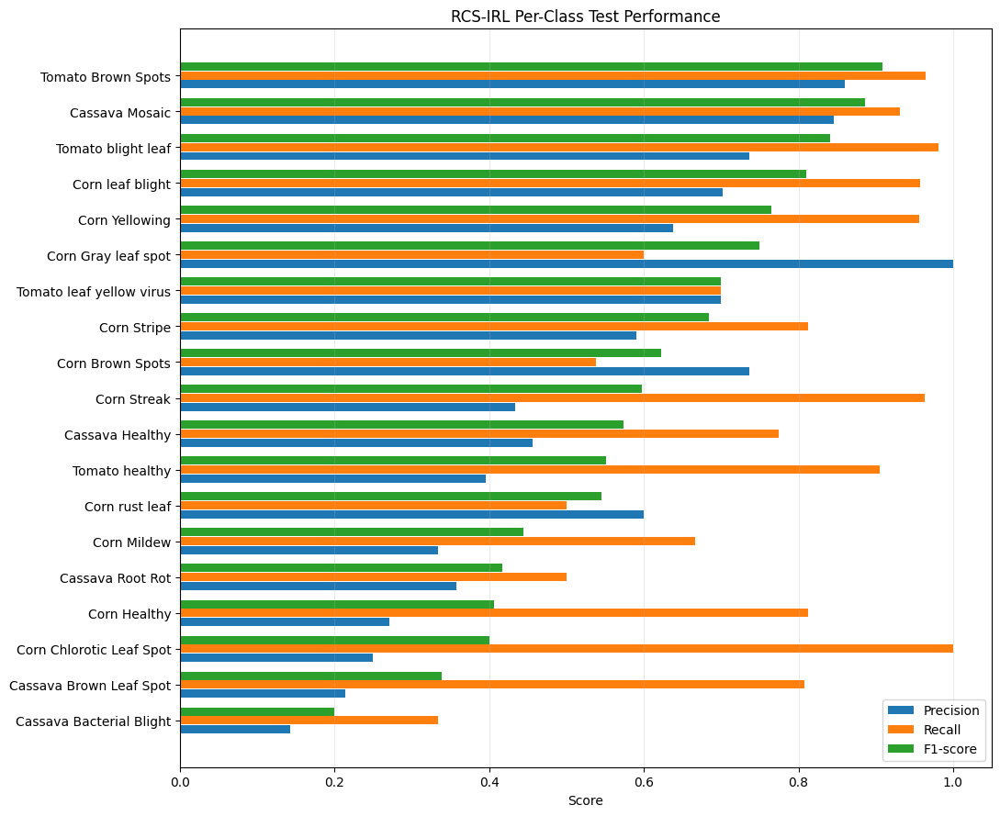

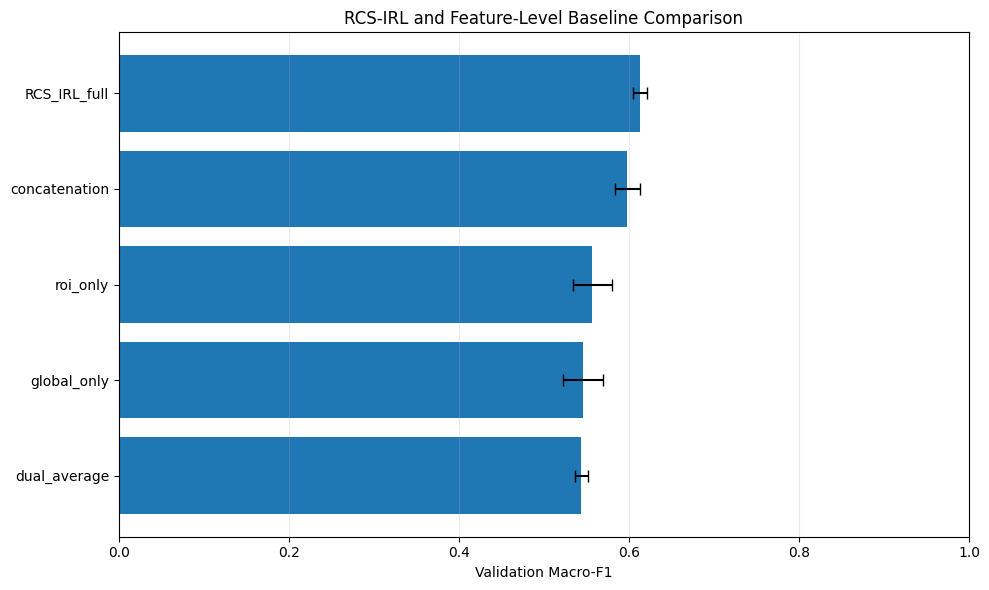

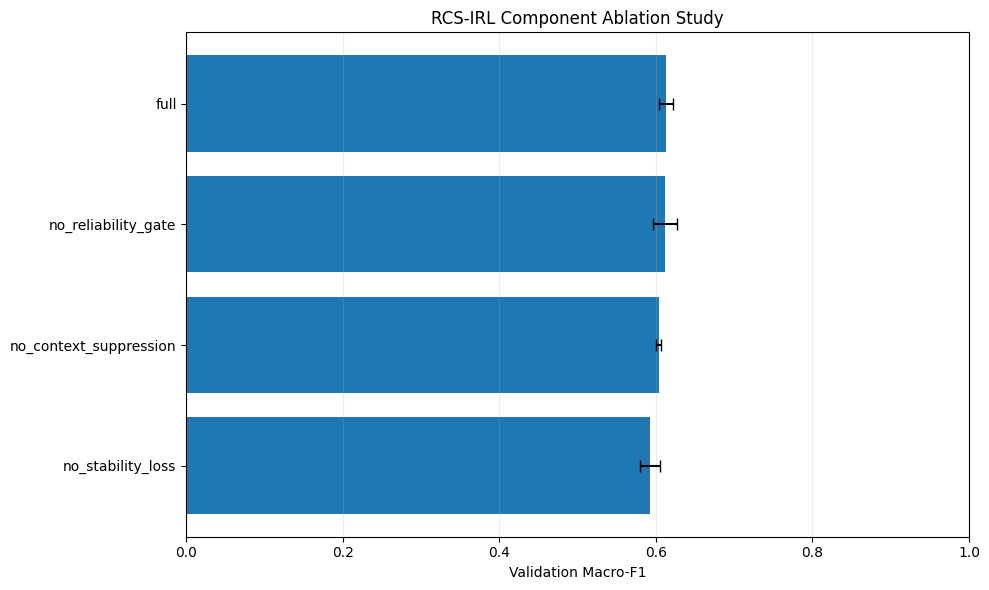

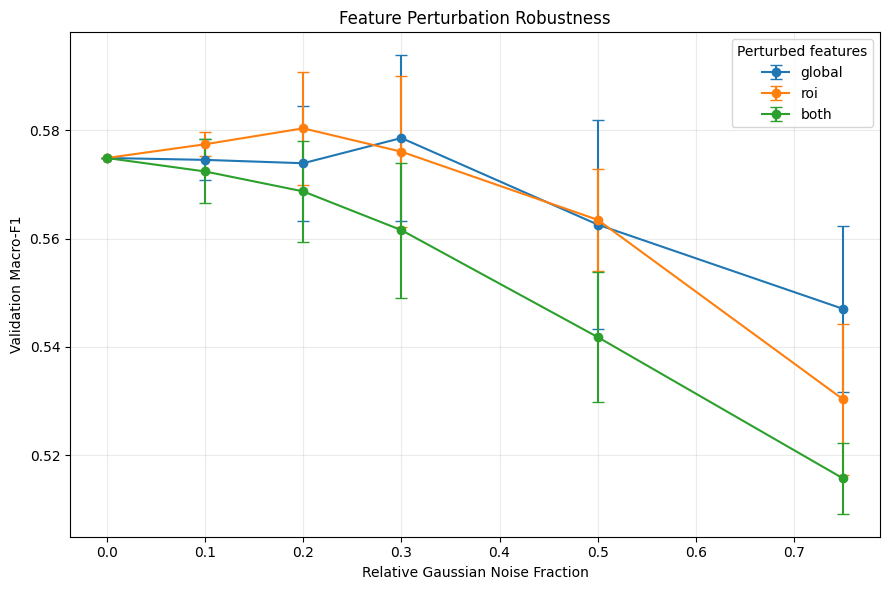


ALL FOUR RESEARCH FIGURES SAVED
fig1_per_class_performance.png 246.84 KB
fig2_baseline_comparison.png 92.02 KB
fig3_ablation_study.png 88.32 KB
fig4_robustness_analysis.png 210.51 KB


In [33]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Figure 1: Per-class performance
plot_df = class_results.sort_values("f1")

fig, ax = plt.subplots(figsize=(11, 9))
y = np.arange(len(plot_df))

ax.barh(y - 0.25, plot_df["precision"], height=0.23, label="Precision")
ax.barh(y, plot_df["recall"], height=0.23, label="Recall")
ax.barh(y + 0.25, plot_df["f1"], height=0.23, label="F1-score")

ax.set_yticks(y)
ax.set_yticklabels(plot_df["class"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("Score")
ax.set_title("RCS-IRL Per-Class Test Performance")
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig1_per_class_performance.png", dpi=300)
plt.show()

# Figure 2: Baseline comparison
comparison = comparison_summary.sort_values("macro_f1_mean")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    comparison["method"],
    comparison["macro_f1_mean"],
    xerr=comparison["macro_f1_std"],
    capsize=4
)
ax.set_xlim(0, 1)
ax.set_xlabel("Validation Macro-F1")
ax.set_title("RCS-IRL and Feature-Level Baseline Comparison")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig2_baseline_comparison.png", dpi=300)
plt.show()

# Figure 3: Ablation study
ablation_plot = ablation_summary.sort_values("macro_f1_mean")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    ablation_plot["method"],
    ablation_plot["macro_f1_mean"],
    xerr=ablation_plot["macro_f1_std"],
    capsize=4
)
ax.set_xlim(0, 1)
ax.set_xlabel("Validation Macro-F1")
ax.set_title("RCS-IRL Component Ablation Study")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig3_ablation_study.png", dpi=300)
plt.show()

# Figure 4: Repeated-seed robustness
robustness_path = TABLE_DIR / "repeated_seed_robustness_summary.csv"
robustness_plot = pd.read_csv(robustness_path)

fig, ax = plt.subplots(figsize=(9, 6))

for mode in ["global", "roi", "both"]:
    subset = robustness_plot[
        robustness_plot["mode"] == mode
    ].sort_values("noise_fraction")

    ax.errorbar(
        subset["noise_fraction"],
        subset["macro_f1_mean"],
        yerr=subset["macro_f1_std"],
        marker="o",
        capsize=4,
        label=mode
    )

ax.set_xlabel("Relative Gaussian Noise Fraction")
ax.set_ylabel("Validation Macro-F1")
ax.set_title("Feature Perturbation Robustness")
ax.legend(title="Perturbed features")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig4_robustness_analysis.png", dpi=300)
plt.show()

print("\nALL FOUR RESEARCH FIGURES SAVED")
for file in sorted(FIGURE_DIR.glob("fig*.png")):
    print(file.name, round(file.stat().st_size / 1024, 2), "KB")


In [34]:

from pathlib import Path
import pandas as pd

print("========== AVAILABLE VARIABLES ==========")

required_variables = [
    "train_history", "history", "training_history",
    "train_losses", "val_losses",
    "val_macro_f1_history", "val_micro_f1_history",
    "model", "feature_model",
    "class_results", "final_metrics",
    "comparison_summary", "ablation_summary",
    "robustness_plot", "test_cache",
    "y_true", "y_pred", "y_prob",
    "train_df", "validation_df", "test_df",
    "PRIMARY_CLASSES"
]

for name in required_variables:
    if name in globals():
        value = globals()[name]
        print(f"{name}: AVAILABLE ({type(value).__name__})")
    else:
        print(f"{name}: NOT AVAILABLE")

print("\n========== SAVED TABLES ==========")
for file in sorted(TABLE_DIR.glob("*")):
    print(file.name, round(file.stat().st_size / 1024, 2), "KB")

print("\n========== SAVED FIGURES ==========")
for file in sorted(FIGURE_DIR.glob("*")):
    print(file.name, round(file.stat().st_size / 1024, 2), "KB")

print("\n========== CHECKPOINTS ==========")
for file in sorted(CHECKPOINT_DIR.glob("*")):
    print(file.name, round(file.stat().st_size / 1024, 2), "KB")

print("\n========== DATASET OUTPUTS ==========")
for file in sorted(OUTPUT_DIR.glob("*")):
    if file.is_file():
        print(file.name, round(file.stat().st_size / 1024, 2), "KB")

print("\nAUDIT COMPLETED")


========== AVAILABLE VARIABLES ==========
train_history: NOT AVAILABLE
history: AVAILABLE (list)
training_history: NOT AVAILABLE
train_losses: NOT AVAILABLE
val_losses: NOT AVAILABLE
val_macro_f1_history: NOT AVAILABLE
val_micro_f1_history: NOT AVAILABLE
model: AVAILABLE (RCS_IRL_Fast)
feature_model: AVAILABLE (RCS_IRL_FeatureModel)
class_results: AVAILABLE (DataFrame)
final_metrics: AVAILABLE (DataFrame)
comparison_summary: AVAILABLE (DataFrame)
ablation_summary: AVAILABLE (DataFrame)
robustness_plot: AVAILABLE (DataFrame)
test_cache: AVAILABLE (dict)
y_true: AVAILABLE (ndarray)
y_pred: AVAILABLE (ndarray)
y_prob: AVAILABLE (ndarray)
train_df: AVAILABLE (DataFrame)
validation_df: NOT AVAILABLE
test_df: AVAILABLE (DataFrame)
PRIMARY_CLASSES: AVAILABLE (list)

========== SAVED TABLES ==========
ablation_raw_results.csv 0.74 KB
ablation_summary.csv 0.43 KB
baseline_comparison_raw.csv 0.69 KB
baseline_comparison_summary.csv 0.51 KB
class_feasibility.csv 1.0 KB
cleaned_all_class_metadata.c

In [35]:

from pathlib import Path
import pandas as pd

history_files = [
    "pilot_training_history.csv",
    "feature_training_history.csv"
]

print("TRAINING HISTORY DETAILS")
for name in history_files:
    path = TABLE_DIR / name
    if path.exists():
        temp = pd.read_csv(path)
        print("\n", name)
        print("Columns:", temp.columns.tolist())
        display(temp.head(3))

print("\nANNOTATION VARIABLES")
for name in ["df", "image_lookup", "test_dataset_fast", "CSV_PATH"]:
    print(name, "AVAILABLE" if name in globals() else "NOT AVAILABLE")

if "df" in globals():
    print("\nAnnotation dataframe shape:", df.shape)
    print("Annotation columns:", df.columns.tolist())

if "test_dataset_fast" in globals():
    print("\nTest dataset length:", len(test_dataset_fast))


TRAINING HISTORY DETAILS

 pilot_training_history.csv
Columns: ['epoch', 'train_loss', 'val_loss', 'val_macro_f1', 'val_micro_f1', 'seconds']


,epoch,train_loss,val_loss,val_macro_f1,val_micro_f1,seconds
0,1,0.968825,0.582414,0.141139,0.531927,445.782006
1,2,0.747200,0.478377,0.254554,0.614182,421.089438



 feature_training_history.csv
Columns: ['epoch', 'train_loss', 'val_loss', 'val_macro_f1', 'val_micro_f1', 'seconds']


,epoch,train_loss,val_loss,val_macro_f1,val_micro_f1,seconds
0,1,0.597056,0.305621,0.336536,0.601835,2.465911
1,2,0.373289,0.241014,0.429722,0.644308,1.428970
2,3,0.294882,0.214332,0.489880,0.696954,1.418723



ANNOTATION VARIABLES
df AVAILABLE
image_lookup AVAILABLE
test_dataset_fast AVAILABLE
CSV_PATH AVAILABLE

Annotation dataframe shape: (8580, 8)
Annotation columns: ['filename', 'width', 'height', 'class', 'xmin', 'ymin', 'xmax', 'ymax']

Test dataset length: 728


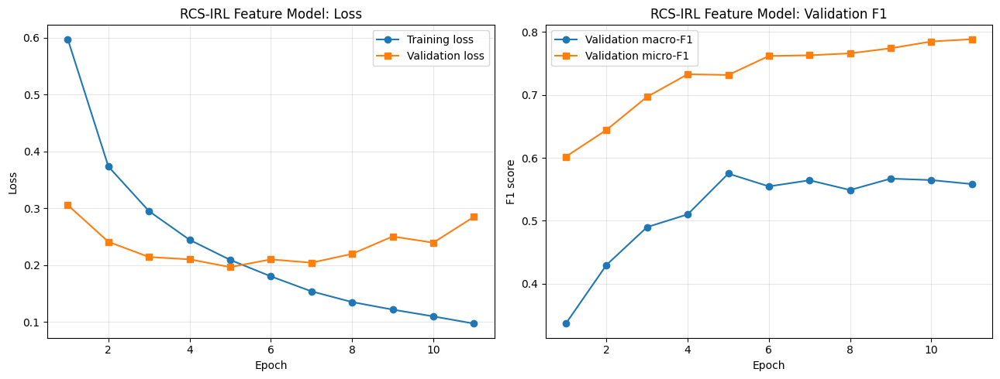

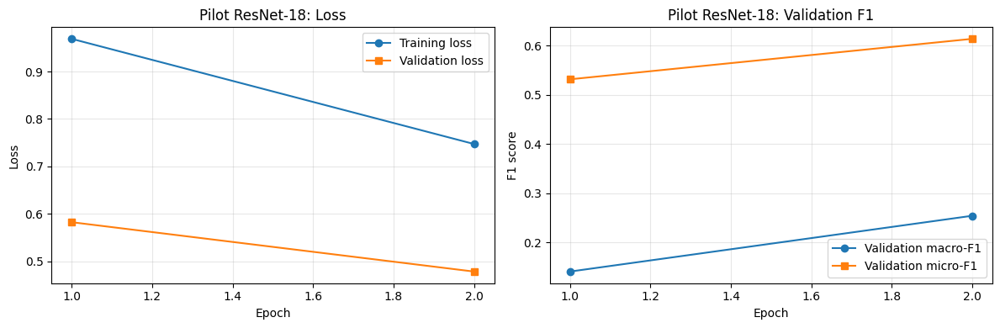

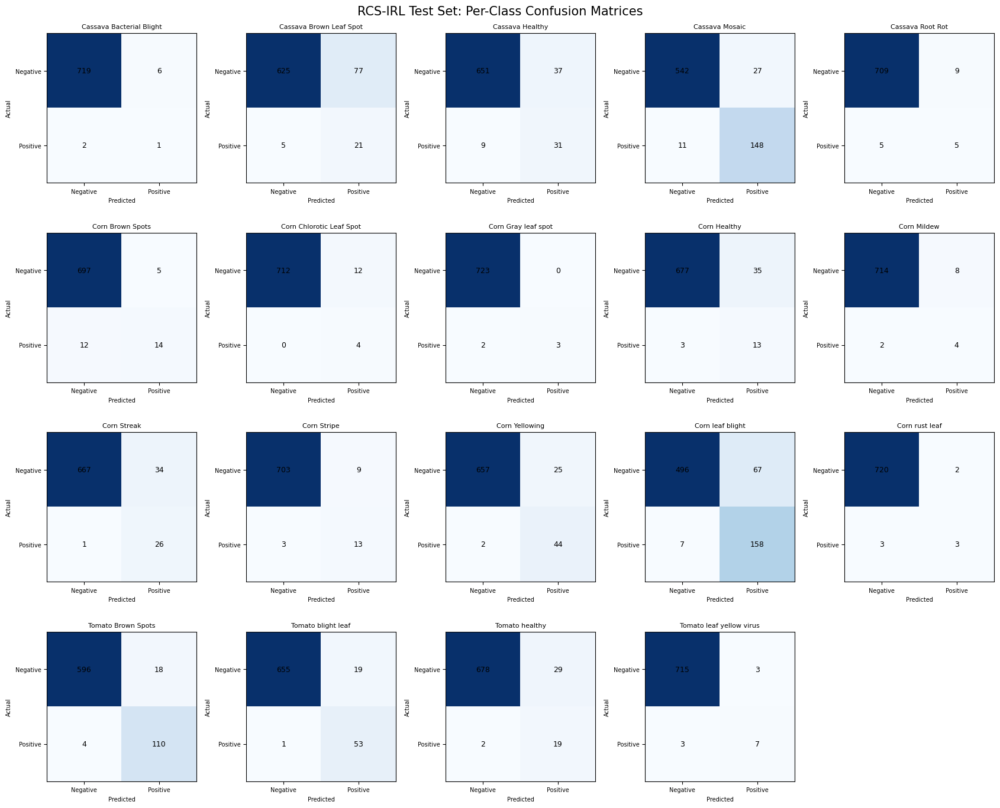

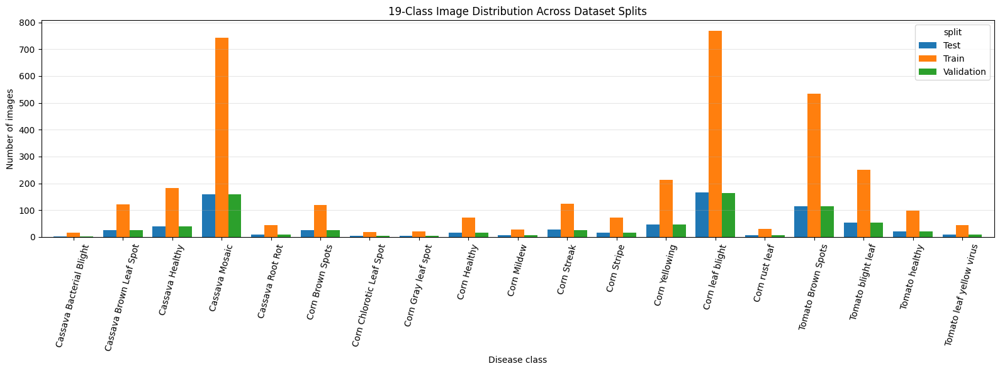

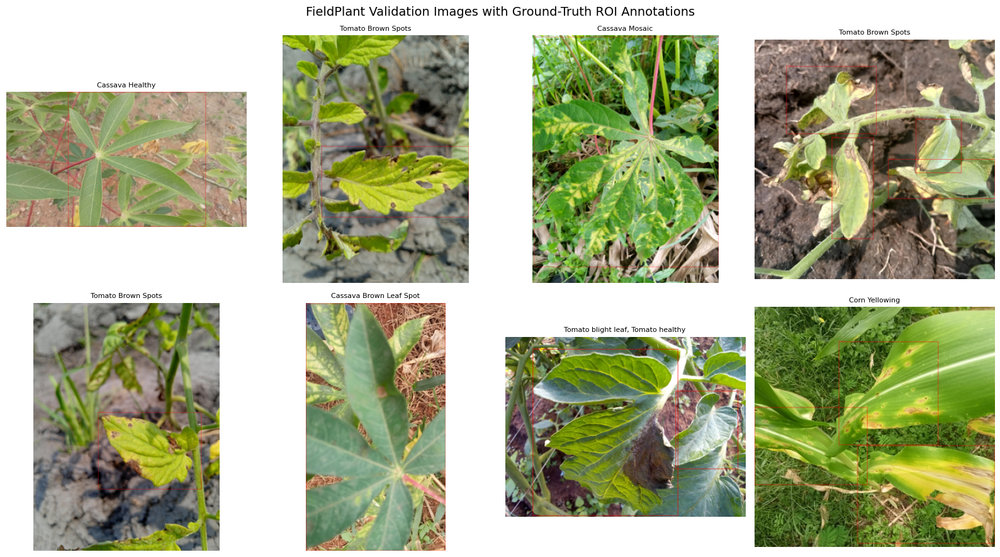


GENERATED FIGURES
fig1_per_class_performance.png 246.84 KB
fig2_baseline_comparison.png 92.02 KB
fig3_ablation_study.png 88.32 KB
fig4_robustness_analysis.png 210.51 KB
fig5_feature_training_curves.png 207.48 KB
fig6_pilot_training_curves.png 164.82 KB
fig7_test_multilabel_confusion_matrices.png 353.48 KB
fig8_class_distribution_by_split.png 455.34 KB
fig9_validation_leaf_roi_examples.png 4430.72 KB

GENERATED TABLES
ablation_raw_results.csv
ablation_summary.csv
baseline_comparison_raw.csv
baseline_comparison_summary.csv
class_distribution_by_split.csv
class_feasibility.csv
cleaned_all_class_metadata.csv
conservative_threshold_report.csv
dimension_mismatches.csv
feature_distribution_audit.csv
feature_model_validation_report.csv
feature_robustness_results.csv
feature_training_history.csv
final_class_counts.csv
final_test_metrics.csv
final_test_per_class_results.csv
image_level_class_distribution.csv
image_level_metadata.csv
multilabel_distribution_by_split.csv
per_class_validation_repo

In [36]:

import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageDraw
from sklearn.metrics import multilabel_confusion_matrix

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Load saved training histories
pilot_history = pd.read_csv(TABLE_DIR / "pilot_training_history.csv")
feature_history = pd.read_csv(TABLE_DIR / "feature_training_history.csv")

# 1. Feature-model training and validation curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(feature_history["epoch"], feature_history["train_loss"], marker="o", label="Training loss")
axes[0].plot(feature_history["epoch"], feature_history["val_loss"], marker="s", label="Validation loss")
axes[0].set_title("RCS-IRL Feature Model: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(feature_history["epoch"], feature_history["val_macro_f1"], marker="o", label="Validation macro-F1")
axes[1].plot(feature_history["epoch"], feature_history["val_micro_f1"], marker="s", label="Validation micro-F1")
axes[1].set_title("RCS-IRL Feature Model: Validation F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1 score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig5_feature_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 2. Pilot model training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(pilot_history["epoch"], pilot_history["train_loss"], marker="o", label="Training loss")
axes[0].plot(pilot_history["epoch"], pilot_history["val_loss"], marker="s", label="Validation loss")
axes[0].set_title("Pilot ResNet-18: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(pilot_history["epoch"], pilot_history["val_macro_f1"], marker="o", label="Validation macro-F1")
axes[1].plot(pilot_history["epoch"], pilot_history["val_micro_f1"], marker="s", label="Validation micro-F1")
axes[1].set_title("Pilot ResNet-18: Validation F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("F1 score")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig6_pilot_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 3. Per-class multilabel confusion matrices
cm_values = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(4, 5, figsize=(17, 14))
axes = axes.flatten()

for i, class_name in enumerate(PRIMARY_CLASSES):
    cm = cm_values[i]
    ax = axes[i]
    ax.imshow(cm, cmap="Blues")
    ax.set_title(class_name, fontsize=8)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Negative", "Positive"], fontsize=7)
    ax.set_yticklabels(["Negative", "Positive"], fontsize=7)
    ax.set_xlabel("Predicted", fontsize=7)
    ax.set_ylabel("Actual", fontsize=7)

    for r in range(2):
        for c in range(2):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=9)

for j in range(len(PRIMARY_CLASSES), len(axes)):
    axes[j].axis("off")

plt.suptitle("RCS-IRL Test Set: Per-Class Confusion Matrices", fontsize=15)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig7_test_multilabel_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# Save confusion matrix values
cm_rows = []
for i, class_name in enumerate(PRIMARY_CLASSES):
    tn, fp, fn, tp = cm_values[i].ravel()
    cm_rows.append({
        "class": class_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

pd.DataFrame(cm_rows).to_csv(TABLE_DIR / "test_confusion_matrix_values.csv", index=False)

# 4. Load validation metadata
val_meta = pd.read_csv(TABLE_DIR / "validation_metadata.csv")

def parse_labels(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        return ast.literal_eval(value)
    except Exception:
        return [str(value)]

if "labels_primary" in val_meta.columns:
    val_meta["labels_primary"] = val_meta["labels_primary"].apply(parse_labels)
elif "labels" in val_meta.columns:
    val_meta["labels_primary"] = val_meta["labels"].apply(parse_labels)
else:
    raise ValueError("No label column found in validation metadata.")

# 5. Dataset class distribution across splits
split_files = {
    "Train": TABLE_DIR / "train_metadata.csv",
    "Validation": TABLE_DIR / "validation_metadata.csv",
    "Test": TABLE_DIR / "test_metadata.csv"
}

distribution_rows = []

for split_name, file_path in split_files.items():
    split_data = pd.read_csv(file_path)
    label_column = "labels_primary" if "labels_primary" in split_data.columns else "labels"
    labels = split_data[label_column].apply(parse_labels)

    for class_name in PRIMARY_CLASSES:
        count = sum(class_name in image_labels for image_labels in labels)
        distribution_rows.append({
            "split": split_name,
            "class": class_name,
            "image_count": count
        })

distribution_df = pd.DataFrame(distribution_rows)
distribution_df.to_csv(TABLE_DIR / "class_distribution_by_split.csv", index=False)

pivot = distribution_df.pivot(index="class", columns="split", values="image_count")
pivot = pivot.reindex(PRIMARY_CLASSES)

ax = pivot.plot(kind="bar", figsize=(16, 6), width=0.8)
ax.set_title("19-Class Image Distribution Across Dataset Splits")
ax.set_xlabel("Disease class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=75)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig8_class_distribution_by_split.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 6. Multi-label image distribution
multi_rows = []

for split_name, file_path in split_files.items():
    split_data = pd.read_csv(file_path)
    label_column = "labels_primary" if "labels_primary" in split_data.columns else "labels"
    label_lists = split_data[label_column].apply(parse_labels)

    counts = pd.Series([len(x) for x in label_lists]).value_counts().sort_index()

    for label_count, image_count in counts.items():
        multi_rows.append({
            "split": split_name,
            "number_of_labels": int(label_count),
            "image_count": int(image_count)
        })

multi_df = pd.DataFrame(multi_rows)
multi_df.to_csv(TABLE_DIR / "multilabel_distribution_by_split.csv", index=False)

# 7. Validation leaf images with annotated ROI boxes
sample_rows = val_meta.sample(n=min(8, len(val_meta)), random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
axes = axes.flatten()

for ax, (_, record) in zip(axes, sample_rows.iterrows()):
    image_path = Path(record["path"])
    filename = record["filename"]

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    boxes = df[
        (df["filename"] == filename) &
        (df["class"].isin(PRIMARY_CLASSES))
    ]

    for _, box in boxes.iterrows():
        coords = (
            int(box["xmin"]), int(box["ymin"]),
            int(box["xmax"]), int(box["ymax"])
        )
        draw.rectangle(coords, outline="red", width=4)
        draw.text(
            (coords[0], max(0, coords[1] - 15)),
            str(box["class"]),
            fill="red"
        )

    image.thumbnail((450, 350))
    ax.imshow(image)
    ax.set_title(", ".join(record["labels_primary"])[:65], fontsize=8)
    ax.axis("off")

for j in range(len(sample_rows), len(axes)):
    axes[j].axis("off")

plt.suptitle("FieldPlant Validation Images with Ground-Truth ROI Annotations", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "fig9_validation_leaf_roi_examples.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 8. Save consolidated experiment summary
print("\nGENERATED FIGURES")
for file in sorted(FIGURE_DIR.glob("fig*.png")):
    print(file.name, round(file.stat().st_size / 1024, 2), "KB")

print("\nGENERATED TABLES")
for file in sorted(TABLE_DIR.glob("*")):
    if file.is_file():
        print(file.name)

print("\nSTEP 29 COMPLETED")


In [37]:

import os
import json
import zipfile
from pathlib import Path
from datetime import datetime

PROJECT_DIR = Path("/content/RCS_IRL")
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

# Create research documentation
readme = """
RCS-IRL RESEARCH EXPERIMENT PACKAGE

Research title:
Reliability-Guided Context-Suppressed Invariant Representation
Learning for Robust Field Crop Disease Recognition

Dataset:
FieldPlant - Kaggle dataset by bloox2
https://www.kaggle.com/datasets/bloox2/fieldplant

TASK:
Multi-label classification of 19 crop disease classes.

DATASET AUDIT:
Original annotated images: 5156
Unique visual groups: 4925
Conflicting duplicate groups excluded: 37
Cleaned independent images: 4888
Primary benchmark images: 4816
Primary classes: 19

SPLIT:
Training: 3369 images
Validation: 719 images
Test: 728 images

The split was created using iterative multilabel stratification
after duplicate grouping. No duplicate image hashes overlap
between splits.

FINAL TEST RESULTS:
Macro Precision: 0.5401
Macro Recall: 0.7740
Macro F1: 0.6022
Micro Precision: 0.6160
Micro Recall: 0.8979
Micro F1: 0.7307
Mean Average Precision: 0.6856
Macro ROC-AUC: 0.9815
Hamming Loss: 0.0361

FINAL EVALUATION:
The test threshold was fixed at 0.5.
No threshold tuning was performed on the test set.

MODEL:
The implementation uses a two-stage procedure:
1. ResNet-18 pilot feature extraction and fine-tuning.
2. Feature-level RCS-IRL context suppression, reliability
   estimation, feature fusion and stability regularization.

The model uses annotation-guided ROI crops from bounding boxes.
The dataset does not provide pixel-level segmentation masks.

EXPERIMENTS:
- Feature-level baseline comparisons
- Context suppression ablation
- Reliability gate ablation
- Stability loss ablation
- Repeated-seed feature perturbation experiments
- Per-class test evaluation
- Multilabel confusion matrices

IMPORTANT SCIENTIFIC LIMITATIONS:
- The dataset is from one source.
- The test split is not an independent farm or geographic domain.
- Synthetic feature perturbations are not equivalent to
  real-world environmental robustness testing.
- Baseline and ablation comparisons are feature-level experiments.
- The implementation should not be described as fully end-to-end.
- Validation and test results must be reported separately.
- No external published SOTA comparison is included in this package.
- Do not claim unseen-domain generalization.

All numerical results in this package are recorded experiment outputs.
Do not invent or modify metrics when preparing the manuscript.

NOTE:
The executable Google Colab notebook is downloaded separately
using File > Download > Download .ipynb.
"""

readme_path = OUTPUT_DIR / "RESEARCH_PACKAGE_README.txt"
readme_path.write_text(readme, encoding="utf-8")

# Save experiment configuration and final metrics
experiment_info = {
    "project": "RCS-IRL",
    "dataset": "FieldPlant",
    "dataset_source": "bloox2/fieldplant",
    "task": "19-class multi-label crop disease classification",
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "backbone": "ResNet-18",
    "device": str(device),
    "train_images": 3369,
    "validation_images": 719,
    "test_images": 728,
    "number_of_classes": len(PRIMARY_CLASSES),
    "test_threshold": 0.5,
    "test_macro_f1": 0.6022,
    "test_micro_f1": 0.7307,
    "test_map": 0.6856,
    "test_macro_roc_auc": 0.9815,
    "test_hamming_loss": 0.0361,
    "package_created": datetime.now().isoformat()
}

with open(OUTPUT_DIR / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(experiment_info, f, indent=4)

# Create package
zip_path = Path("/content/RCS_IRL_Final_Research_Package.zip")

included_files = []

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for folder in [FIGURE_DIR, TABLE_DIR, CHECKPOINT_DIR, OUTPUT_DIR]:
        for file in folder.rglob("*"):
            if file.is_file() and file != zip_path:
                archive.write(file, file.relative_to(PROJECT_DIR))
                included_files.append(file)

    # Include duplicate audit records and dataset-cleaning records
    for file in PROJECT_DIR.rglob("*.json"):
        if file.is_file() and file not in included_files:
            archive.write(file, file.relative_to(PROJECT_DIR))
            included_files.append(file)

print("PACKAGE CREATED")
print("Files included:", len(included_files))
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")
print("Location:", zip_path)

# Download package
from google.colab import files
files.download(str(zip_path))


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/figures/fig2_baseline_comparison.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/figures/fig1_per_class_performance.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/figures/image_level_class_distribution.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/figures/fig5_feature_training_curves.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/figures/fig9_validation_leaf_roi_examples.png'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Dupli

PACKAGE CREATED
Files included: 89
ZIP size: 139.81 MB
Location: /content/RCS_IRL_Final_Research_Package.zip


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/tables/final_test_metrics.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/tables/class_feasibility.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/tables/final_class_counts.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/tables/feature_training_history.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/tables/ablation_summary.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)
/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'outputs/tables/feature_distribution_audit

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>